# Structural Characteristics (Constructed + Ground-truth)

> **Important: focus on tabular camera-ready output!**

## Pointwise

1. Tree: size
2. Node: depth
3. Node: degree
4. Path: rtl_paths
5. Path: anc_paths

## Pairwise 

1. Node Jaccard Index
   1. _with overview_
3. Path Jaccard Index
   1. _with overview_
4. APTED tree similarity
   1. _with change breakdown_

## Preamble

In [1]:
!cd ../../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
    Using cached setuptools-82.0.1-py3-none-any.whl.metadata (6.5 kB)
  Using cached setuptools-82.0.1-py3-none-any.whl (1.0 MB)
  ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
  torch 2.12.0 requires setuptools<82, but you have setuptools 82.0.1 which is incompatible.
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  r

In [118]:
from lxml import etree
import apted

In [3]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [4]:
import tol_colors as tcls

In [5]:
import itertools as itlx
import json
from pathlib import Path
import re 

In [6]:
from typing import TypedDict, Any

In [7]:
from IPython.display import display, display_markdown

In [8]:
tcls.set_default_colors()
plt.set_cmap(mpl.cm.tab20)

New config line: axes.prop_cycle : cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
Injecting line in file '/Users/mitjaorlov/.matplotlib/matplotlibrc'


<Figure size 640x480 with 0 Axes>

### Utilities

In [9]:
from warnings import warn

class OutcomeContainer[T](TypedDict):
    value: T | None
    error: str | None

def do_or_error(func) -> OutcomeContainer[Any]: 
    def wrapper(*args, **kwargs):
        try:
            return {"value": func(*args, **kwargs), "error": None}
        except Exception as e:
            return {"error": f"{type(e)}: {str(e)}", "value": None}
    return wrapper

def do_on_value(func):
    def wrapper(c: OutcomeContainer[Any], *args, **kwargs):
        if c["value"] is not None:
            return func(c["value"], *args, **kwargs)
        else:
            return c
    return wrapper

In [10]:
EXPERIMENT_BASE_DIR = "../../../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

In [11]:
def ok_results(df):
    return df[df["success"]]

### Constructs

In [12]:
@do_or_error
def parse_xml_file(path: str | Path):
    return etree.parse(path)

@do_or_error
def parse_xml_string(data: str):
    return etree.fromstring(data.encode())

@do_on_value
def parse_xml_content(xml_content: Any):
    return parse_xml_string(str(xml_content))

In [13]:
@do_or_error
def resolve_xml_content(r: dict) -> str:
    return r['resolutions'][0]['working_copy_xml_blueprint']["content"]    

In [14]:
@do_on_value
@do_or_error
def cleanup_gap_failures(xml_data:str):
    return re.sub(r"\{\{GAP_([0-9]+)[^\}]*\}+", r"not-derived-\1", xml_data)

@do_on_value
@do_or_error
def cleanup_special_characters(xml_data:str):
    return re.sub("&", "&amp;", xml_data)

In [15]:
class NodeInfo(TypedDict):
    tag: str
    degree: int
    depth: int
    is_leaf: bool # <=> (degree == 0) 
    attributes: dict
    text: str
    path: str | None

class TreeInfo(TypedDict):
    size: int # <=> (|_nodes|)
    _nodes: list[NodeInfo]

def project_public(d: dict):
    return {k:v for k,v in d.items() if not str(k).startswith("_")}

In [16]:
def get_root(tree):
    """Retrieves a root of the provided tree"""
    if hasattr(tree, "getroot"):
        return tree.getroot()
    return tree

In [17]:
@do_on_value
@do_or_error
def get_tree_info(tree) -> TreeInfo:
    return _get_tree_info(tree)

def _get_tree_info(tree) -> TreeInfo:
    root = etree.ElementTree(get_root(tree))
    
    def _get_node_info(node) -> NodeInfo:
        return {
            "tag": node.tag,
            "depth": len(list(node.iterancestors())),
            "degree": len(node),
            "is_leaf": len(node) == 0,
            "attributes": node.attrib,
            "has_attributes": bool(node.attrib),
            "text": node.text,
            "has_text": bool(node.text.strip()) if node.text else False,
            "path": None if isinstance(node, etree._Comment) else root.getelementpath(node)
        }
    
    nodes = list(root.iter())
    return {
        "size": len(nodes), 
        "_nodes": list(map(_get_node_info, nodes))
    }

## Data collection

In [18]:
gbif_cases = pd.read_csv("../../runtime/full_gbif_cases.csv")
experiment_results = pd.read_csv("../../runtime/experiment_cross_scenarios_cases.log.csv")

In [19]:
dwc_data_results = experiment_results[(experiment_results["schema"] == "dwc") & (experiment_results["strategy"] == "data-focus")]
dwc_author_results = experiment_results[(experiment_results["schema"] == "dwc") & (experiment_results["strategy"] == "author-focus")]

eml_data_results = experiment_results[(experiment_results["schema"] == "eml") & (experiment_results["strategy"] == "data-focus")]
eml_author_results = experiment_results[(experiment_results["schema"] == "eml") & (experiment_results["strategy"] == "author-focus")]

In [20]:
result_groups = {
    "DwC-T~Data": dwc_data_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(),
    "DwC-T~Author": dwc_author_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(), 
    "EML~Data": eml_data_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(), 
    "EML~Author": eml_author_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(),
}
result_group_2_ground_truth = {
    "DwC-T~Data": "ground_truth_metadata_dwc",
    "DwC-T~Author": "ground_truth_metadata_dwc", 
    "EML~Data": "ground_truth_metadata_eml", 
    "EML~Author": "ground_truth_metadata_eml",
}
cross_group_key_pairs = {
    ("DwC-T~Data", "DwC-T~Author"),
    ("EML~Data", "EML~Author"),
}

for g, rs in result_groups.items():
    display(f"> --- Result Group: `{g}` ---")
    display(rs.describe())

'> --- Result Group: `DwC-T~Data` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,164.296089,0.0,0.0,153.513966,2.0,89.000000,46.359027,1.778160e+09
std,99.617169,0.0,0.0,99.156009,0.0,51.816986,77.392903,1.187505e+04
min,0.000000,0.0,0.0,0.000000,2.0,0.000000,12.870421,1.778149e+09
25%,84.500000,0.0,0.0,68.000000,2.0,44.500000,22.477583,1.778155e+09
50%,159.000000,0.0,0.0,151.000000,2.0,89.000000,30.010789,1.778159e+09
75%,263.500000,0.0,0.0,233.500000,2.0,133.500000,43.288641,1.778165e+09
max,444.000000,0.0,0.0,336.000000,2.0,178.000000,765.560462,1.778260e+09


'> --- Result Group: `DwC-T~Author` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,194.670391,4.0,4.0,153.513966,2.0,89.000000,42.249969,1.778161e+09
std,109.385350,0.0,0.0,99.156009,0.0,51.816986,54.813842,1.193789e+04
min,10.000000,4.0,4.0,0.000000,2.0,0.000000,14.248861,1.778150e+09
25%,114.500000,4.0,4.0,68.000000,2.0,44.500000,24.495313,1.778156e+09
50%,189.000000,4.0,4.0,151.000000,2.0,89.000000,29.604584,1.778160e+09
75%,310.500000,4.0,4.0,233.500000,2.0,133.500000,42.310426,1.778167e+09
max,445.000000,4.0,4.0,336.000000,2.0,178.000000,478.510206,1.778260e+09


'> --- Result Group: `EML~Data` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,515.670391,8.0,8.0,153.513966,2.0,89.000000,445.775805,1.778304e+09
std,97.111935,0.0,0.0,99.156009,0.0,51.816986,394.417847,3.889963e+04
min,354.000000,8.0,8.0,0.000000,2.0,0.000000,38.520714,1.778230e+09
25%,439.500000,8.0,8.0,68.000000,2.0,44.500000,312.525535,1.778249e+09
50%,527.000000,8.0,8.0,151.000000,2.0,89.000000,407.317098,1.778325e+09
75%,611.500000,8.0,8.0,233.500000,2.0,133.500000,496.024076,1.778331e+09
max,702.000000,8.0,8.0,336.000000,2.0,178.000000,4997.299114,1.778334e+09


'> --- Result Group: `EML~Author` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,555.363128,12.0,12.0,153.513966,2.0,89.000000,261.103811,1.778308e+09
std,108.616256,0.0,0.0,99.156009,0.0,51.816986,67.038688,3.772579e+04
min,356.000000,12.0,12.0,0.000000,2.0,0.000000,51.728838,1.778231e+09
25%,480.500000,12.0,12.0,68.000000,2.0,44.500000,221.043937,1.778322e+09
50%,567.000000,12.0,12.0,151.000000,2.0,89.000000,264.250012,1.778327e+09
75%,666.500000,12.0,12.0,233.500000,2.0,133.500000,305.515517,1.778333e+09
max,715.000000,12.0,12.0,336.000000,2.0,178.000000,466.105851,1.778335e+09


In [21]:
for g, rs in result_groups.items():
    result_groups[g]["outcome_dict"] = rs["outcome_json"].apply(json.loads)
result_groups[g]["outcome_dict"].head()

0    {'messages': [], 'settings': {'runtime_config'...
1    {'status': 'exception', 'error_content': ''gap...
2    {'messages': [], 'settings': {'runtime_config'...
3    {'messages': [], 'settings': {'runtime_config'...
4    {'messages': [], 'settings': {'runtime_config'...
Name: outcome_dict, dtype: object

In [22]:
for g, rs in result_groups.items():
    result_groups[g]["outcome_metadata_xml"] = rs["outcome_dict"].apply(resolve_xml_content)
result_groups[g]["outcome_metadata_xml"].head()

0    {'value': '<?xml version="1.0" encoding="UTF-8...
1    {'error': '<class 'KeyError'>: 'resolutions'',...
2    {'value': '<?xml version="1.0" encoding="UTF-8...
3    {'value': '<?xml version="1.0" encoding="UTF-8...
4    {'value': '<?xml version="1.0" encoding="UTF-8...
Name: outcome_metadata_xml, dtype: object

In [23]:
for g, rs in result_groups.items():
    result_groups[g]["outcome_metadata_xml.clean"] = rs["outcome_metadata_xml"].apply(cleanup_gap_failures).apply(cleanup_special_characters)
    result_groups[g]["constructed.xml_tree"] = result_groups[g]["outcome_metadata_xml.clean"].apply(parse_xml_content)
result_groups[g]["outcome_metadata_xml.clean"].head(), result_groups[g]["constructed.xml_tree"].head()

(0    {'value': '<?xml version="1.0" encoding="UTF-8...
 1    {'error': '<class 'KeyError'>: 'resolutions'',...
 2    {'value': '<?xml version="1.0" encoding="UTF-8...
 3    {'value': '<?xml version="1.0" encoding="UTF-8...
 4    {'value': '<?xml version="1.0" encoding="UTF-8...
 Name: outcome_metadata_xml.clean, dtype: object,
 0    {'value': [[<Element title at 0x11c9d4bc0>, <E...
 1    {'error': '<class 'KeyError'>: 'resolutions'',...
 2    {'value': [[<Element title at 0x11c9d45c0>, <E...
 3    {'value': [[<Element title at 0x11c9d4cc0>, <E...
 4    {'value': [[<Element title at 0x11c9d4d00>, <E...
 Name: constructed.xml_tree, dtype: object)

In [24]:
def with_ok_constructed_trees(df):
    return df[df["constructed.xml_tree"].apply(lambda x: x["value"] is not None)]

def with_ok_ground_truth_trees(df):
    return df[df["ground_truth.xml_tree"].apply(lambda x: x["value"] is not None)]

In [25]:
for g, rs in result_groups.items():
    gt_key = result_group_2_ground_truth[g]
    result_groups[g]["ground_truth.xml_tree"] = rs[gt_key].apply(grounded_path).apply(parse_xml_file)
result_groups[g]["ground_truth.xml_tree"].head()

0    {'value': <lxml.etree._ElementTree object at 0...
1    {'value': <lxml.etree._ElementTree object at 0...
2    {'value': <lxml.etree._ElementTree object at 0...
3    {'value': <lxml.etree._ElementTree object at 0...
4    {'value': <lxml.etree._ElementTree object at 0...
Name: ground_truth.xml_tree, dtype: object

In [26]:
for g, rs in result_groups.items():
    print(f"--- {g} ---")
    print(result_groups[g].shape[0])
    print(with_ok_constructed_trees(result_groups[g]).shape[0])
    print(ok_results(result_groups[g]).shape[0])

--- DwC-T~Data ---
179
174
179
--- DwC-T~Author ---
179
174
175
--- EML~Data ---
179
150
155
--- EML~Author ---
179
148
158


## Computing Individual Values

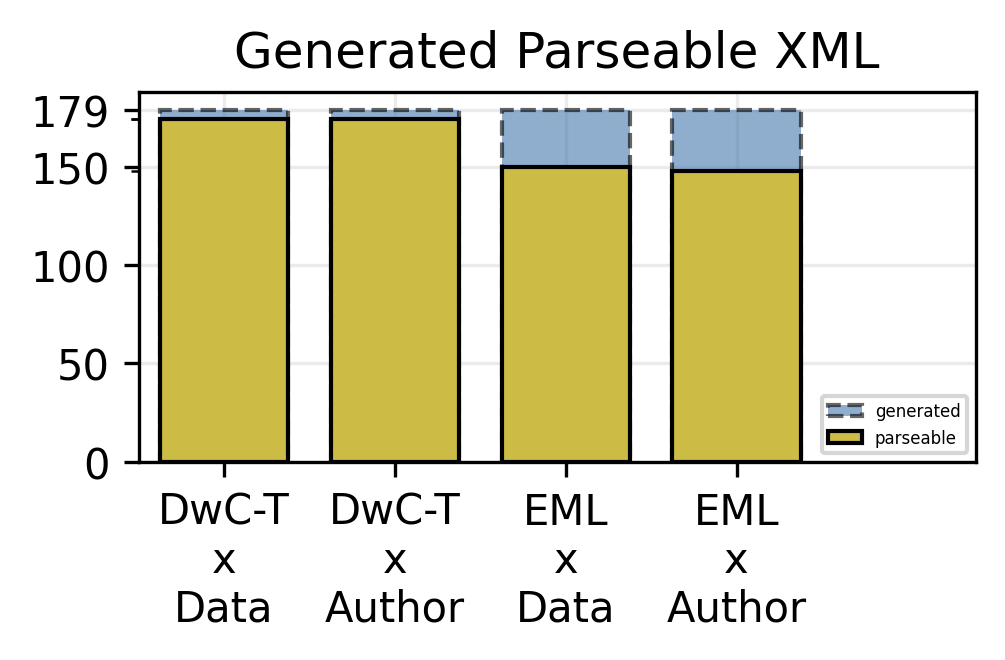

In [27]:
fig, ax = plt.subplots(1,1, dpi=300, figsize=(3.6, 1.6))

experiment_groups = np.array(["\nx\n".join(g.split("~")) for g, rs in result_groups.items()])
experiment_count = np.array([rs.shape[0] for g, rs in result_groups.items()])
ok_experiment_count = np.array([with_ok_constructed_trees(rs).shape[0] for g, rs in result_groups.items()])

ax.set_title("Generated Parseable XML")
ax.bar(experiment_groups, experiment_count, label="generated", color=tcls.bright[0], edgecolor="black", ls="--", alpha=0.6, width=0.75)
ax.bar(experiment_groups, ok_experiment_count, label="parseable", color=tcls.bright[3], edgecolor="black", width=0.75)
ax.set_yticks(ok_experiment_count, minor=True)
ax.set_yticks([0, 50, 100, 150, 179])
ax.set_xlim(-0.5, 4.4)
ax.legend(fontsize=4, loc="lower right")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

In [28]:
for g, rs in result_groups.items():
    result_groups[g]["constructed.xml_tree.characteristics"] = with_ok_constructed_trees(rs)["constructed.xml_tree"].apply(get_tree_info)
result_groups[g]["constructed.xml_tree.characteristics"].head()[0]

{'value': {'size': 47,
  '_nodes': [{'tag': '{https://eml.ecoinformatics.org/eml-2.2.0}eml',
    'depth': 0,
    'degree': 2,
    'is_leaf': False,
    'attributes': {'packageId': '2265c6e2-4ab7-4af2-93af-ba377a7d4e43', 'system': 'knb', '{http://www.w3.org/XML/1998/namespace}lang': 'en'},
    'has_attributes': True,
    'text': '\n  ',
    'has_text': False,
    'path': '.'},
   {'tag': 'dataset',
    'depth': 1,
    'degree': 6,
    'is_leaf': False,
    'attributes': {},
    'has_attributes': False,
    'text': '\n    ',
    'has_text': False,
    'path': 'dataset'},
   {'tag': 'title',
    'depth': 2,
    'degree': 0,
    'is_leaf': True,
    'attributes': {},
    'has_attributes': False,
    'text': 'Renato_PhD',
    'has_text': True,
    'path': 'dataset/title'},
   {'tag': 'creator',
    'depth': 2,
    'degree': 2,
    'is_leaf': False,
    'attributes': {},
    'has_attributes': False,
    'text': '\n      ',
    'has_text': False,
    'path': 'dataset/creator'},
   {'tag': 'in

In [29]:
for g, rs in result_groups.items():
    result_groups[g]["ground_truth.xml_tree.characteristics"] = rs["ground_truth.xml_tree"].apply(get_tree_info)
result_groups[g]["ground_truth.xml_tree.characteristics"].head()[0]

{'value': {'size': 511,
  '_nodes': [{'tag': '{https://eml.ecoinformatics.org/eml-2.2.0}eml',
    'depth': 0,
    'degree': 2,
    'is_leaf': False,
    'attributes': {'{http://www.w3.org/2001/XMLSchema-instance}schemaLocation': 'https://eml.ecoinformatics.org/eml-2.2.0 https://rs.gbif.org/schema/eml-gbif-profile/1.3/eml.xsd', 'packageId': '2265c6e2-4ab7-4af2-93af-ba377a7d4e43/v1.2', 'system': 'http://gbif.org', 'scope': 'system', '{http://www.w3.org/XML/1998/namespace}lang': 'eng'},
    'has_attributes': True,
    'text': '\n    ',
    'has_text': False,
    'path': '.'},
   {'tag': 'dataset',
    'depth': 1,
    'degree': 26,
    'is_leaf': False,
    'attributes': {},
    'has_attributes': False,
    'text': '\n        ',
    'has_text': False,
    'path': 'dataset'},
   {'tag': 'alternateIdentifier',
    'depth': 2,
    'degree': 0,
    'is_leaf': True,
    'attributes': {},
    'has_attributes': False,
    'text': '2265c6e2-4ab7-4af2-93af-ba377a7d4e43',
    'has_text': True,
    '

### Constructed


In [30]:
cons_tree_info_groups = {}
cons_node_info_groups = {}
for g, rs in result_groups.items():
    cons_tree_info_groups[g] = pd.DataFrame.from_records(
        with_ok_constructed_trees(result_groups[g]).apply(
            lambda t: {"case_id": t["case_id"], **project_public(val)} if (val := t["constructed.xml_tree.characteristics"]["value"]) else {"case_id": t["case_id"]}, 
            axis=1
        )
    )
    cons_node_info_groups[g] = pd.DataFrame.from_records(
        itlx.chain.from_iterable(with_ok_constructed_trees(result_groups[g]).apply(
            lambda t: (
                [
                    {"case_id": t["case_id"], **pn} 
                    for pn 
                    in map(project_public, val["_nodes"])
                ] if (val := t["constructed.xml_tree.characteristics"]["value"]) else [{"case_id": t["case_id"]}]
            ), 
            axis=1
        ).tolist())
    )

In [31]:
list([(g,vs["constructed.xml_tree"]) for g,vs in result_groups.items()])

[('DwC-T~Data',
  0      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  1      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  2      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  3      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  4      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
                               ...                        
  174    {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  175    {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  176    {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  177    {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  178    {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  Name: constructed.xml_tree, Length: 179, dtype: object),
 ('DwC-T~Author',
  0      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  1      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  2      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  3      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  4      {'value': [[<

In [32]:
for g,rs in cons_tree_info_groups.items():
    print(g)
    display(rs.describe())

DwC-T~Data


,case_id,size
count,174.000000,174.000000
mean,89.356322,49.149425
std,52.318163,22.960649
min,0.000000,12.000000
25%,43.250000,33.250000
50%,90.500000,45.000000
75%,134.750000,60.750000
max,178.000000,190.000000


DwC-T~Author


,case_id,size
count,174.000000,174.000000
mean,89.350575,49.206897
std,51.515395,22.552771
min,0.000000,12.000000
25%,45.250000,34.000000
50%,89.500000,45.500000
75%,133.750000,61.000000
max,178.000000,186.000000


EML~Data


,case_id,size
count,150.000000,150.000000
mean,88.686667,42.460000
std,53.070314,9.766145
min,0.000000,32.000000
25%,42.250000,34.000000
50%,88.500000,41.000000
75%,134.750000,48.000000
max,178.000000,76.000000


EML~Author


,case_id,size
count,148.000000,148.000000
mean,92.864865,40.094595
std,50.983477,7.939686
min,0.000000,32.000000
25%,49.750000,34.000000
50%,96.000000,38.000000
75%,137.250000,46.000000
max,178.000000,65.000000


In [33]:
for g,rs in cons_node_info_groups.items():
    print(g)
    display(rs.describe(include="all"))

DwC-T~Data


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,8552.000000,8552,8552.000000,8552.000000,8552,8552,8552,975,8552,8552
unique,NaN,8,NaN,NaN,2,2928,2,24,2,332
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},True,\n,False,.
freq,NaN,7310,NaN,NaN,7844,534,8018,267,8285,174
mean,88.918732,NaN,1.959308,0.979654,NaN,NaN,NaN,NaN,NaN,NaN
std,51.588900,NaN,0.377077,6.206240,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,43.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,91.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,134.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


DwC-T~Author


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,8562.000000,8562,8562.000000,8562.000000,8562,8562,8562,984,8562,8562
unique,NaN,8,NaN,NaN,2,2903,2,23,2,330
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},True,\n,False,.
freq,NaN,7308,NaN,NaN,7848,540,8022,270,8292,174
mean,89.333450,NaN,1.959355,0.979678,NaN,NaN,NaN,NaN,NaN,NaN
std,50.609223,NaN,0.377788,6.182620,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,46.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,91.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


EML~Data


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,6369.000000,6369,6369.000000,6369.000000,6369,6369,6369,6238,6369,6369
unique,NaN,319,NaN,NaN,2,133,2,1246,2,706
top,NaN,para,NaN,NaN,False,{},False,\n,False,.
freq,NaN,697,NaN,NaN,3409,5740,5740,1258,3433,150
mean,88.133302,NaN,3.396452,0.976448,NaN,NaN,NaN,NaN,NaN,NaN
std,53.838807,NaN,1.229222,1.310859,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,40.000000,NaN,3.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,88.000000,NaN,4.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,135.000000,NaN,4.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN


EML~Author


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,5934.000000,5934,5934.000000,5934.000000,5934,5934,5934,5811,5934,5934
unique,NaN,297,NaN,NaN,2,133,2,1486,2,558
top,NaN,para,NaN,NaN,False,{},False,\n,False,.
freq,NaN,652,NaN,NaN,3194,5327,5327,1166,3202,148
mean,91.711156,NaN,3.337883,0.975059,NaN,NaN,NaN,NaN,NaN,NaN
std,50.854321,NaN,1.219922,1.282741,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,48.000000,NaN,3.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,92.000000,NaN,3.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,136.000000,NaN,4.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN


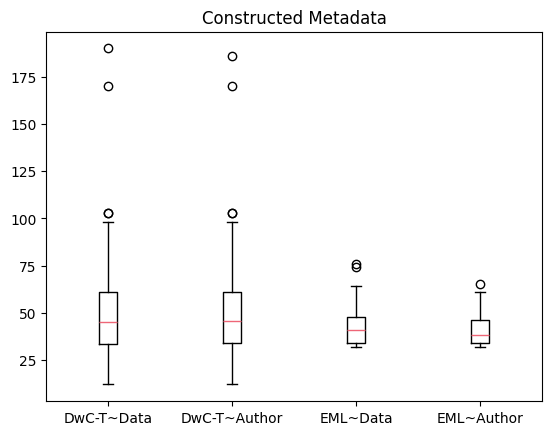

In [34]:
fig,ax = plt.subplots()


ax.set_title("Constructed Metadata")
for i,(g,rs) in enumerate(cons_tree_info_groups.items()):
    ax.boxplot(rs["size"].dropna(), positions=(i,), label=g)
ax.set_xticklabels(list(cons_tree_info_groups.keys()))
# ax.legend()

plt.show()

### Ground Truth

In [35]:
gt_tree_info_groups = {}
gt_node_info_groups = {}
for g, rs in result_groups.items():
    gt_tree_info_groups[g] = pd.DataFrame.from_records(
        result_groups[g].apply(
            lambda t: {"case_id": t["case_id"], **project_public(val)} if (val := t["ground_truth.xml_tree.characteristics"]["value"]) else {"case_id": t["case_id"]}, 
            axis=1
        )
    )
    gt_node_info_groups[g] = pd.DataFrame.from_records(
        itlx.chain.from_iterable(result_groups[g].apply(
            lambda t: (
                [
                    {"case_id": t["case_id"], **pn} 
                    for pn 
                    in map(project_public, val["_nodes"])
                ] if (val := t["ground_truth.xml_tree.characteristics"]["value"]) else [{"case_id": t["case_id"]}]
            ), 
            axis=1
        ).tolist())
    )

In [36]:
for g,rs in gt_tree_info_groups.items():
    print(g)
    display(rs.describe(include="all"))

DwC-T~Data


,case_id,size
count,179.000000,179.000000
mean,89.000000,49.307263
std,51.816986,23.171091
min,0.000000,12.000000
25%,44.500000,33.500000
50%,89.000000,45.000000
75%,133.500000,61.000000
max,178.000000,202.000000


DwC-T~Author


,case_id,size
count,179.000000,179.000000
mean,89.000000,49.307263
std,51.816986,23.171091
min,0.000000,12.000000
25%,44.500000,33.500000
50%,89.000000,45.000000
75%,133.500000,61.000000
max,178.000000,202.000000


EML~Data


,case_id,size
count,179.000000,179.000000
mean,89.000000,299.810056
std,51.816986,494.601131
min,0.000000,31.000000
25%,44.500000,142.000000
50%,89.000000,206.000000
75%,133.500000,331.500000
max,178.000000,6326.000000


EML~Author


,case_id,size
count,179.000000,179.000000
mean,89.000000,299.810056
std,51.816986,494.601131
min,0.000000,31.000000
25%,44.500000,142.000000
50%,89.000000,206.000000
75%,133.500000,331.500000
max,178.000000,6326.000000


In [37]:
for g,rs in gt_node_info_groups.items():
    print(g)
    display(rs.describe(include="all"))

DwC-T~Data


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


DwC-T~Author


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


EML~Data


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,53666.000000,53666,53666.000000,53666.000000,53666,53666,53666,53207,53666,53660
unique,NaN,122,NaN,NaN,2,661,2,15232,2,10769
top,NaN,taxonomicClassification,NaN,NaN,True,{},False,\n,True,.
freq,NaN,5259,NaN,NaN,35924,51180,51180,4070,35886,179
mean,94.440018,NaN,3.823166,0.996665,NaN,NaN,NaN,NaN,NaN,NaN
std,49.492698,NaN,1.006971,9.408301,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,52.000000,NaN,3.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,101.000000,NaN,4.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,129.000000,NaN,5.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN


EML~Author


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,53666.000000,53666,53666.000000,53666.000000,53666,53666,53666,53207,53666,53660
unique,NaN,122,NaN,NaN,2,661,2,15232,2,10769
top,NaN,taxonomicClassification,NaN,NaN,True,{},False,\n,True,.
freq,NaN,5259,NaN,NaN,35924,51180,51180,4070,35886,179
mean,94.440018,NaN,3.823166,0.996665,NaN,NaN,NaN,NaN,NaN,NaN
std,49.492698,NaN,1.006971,9.408301,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,52.000000,NaN,3.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,101.000000,NaN,4.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,129.000000,NaN,5.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN


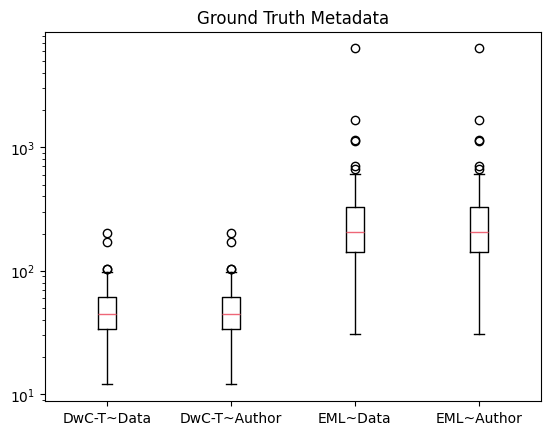

In [38]:
fig,ax = plt.subplots()


ax.set_title("Ground Truth Metadata")
ax.set_yscale("log")
for i,(g,rs) in enumerate(gt_tree_info_groups.items()):
    ax.boxplot(rs["size"].dropna(), positions=(i,), label=g)
ax.set_xticklabels(list(cons_tree_info_groups.keys()))
# ax.legend()

plt.show()

## Reporting Pointwise

In [39]:
def fmt_result_group_title_multiline(t: str)->str:
    return "\nx\n".join(t.split("~"))

def fmt_result_group_title_oneline(t: str)->str:
    return " x ".join(t.split("~"))

In [40]:
for g, rs in result_groups.items():
    print(f"--- {g} ---")
    print(f"total results: {result_groups[g].shape[0]}")
    print(f"parsed_trees: {with_ok_constructed_trees(result_groups[g]).shape[0]}")
    print(f"constructed trees: {ok_results(result_groups[g]).shape[0]}")

--- DwC-T~Data ---
total results: 179
parsed_trees: 174
constructed trees: 179
--- DwC-T~Author ---
total results: 179
parsed_trees: 174
constructed trees: 175
--- EML~Data ---
total results: 179
parsed_trees: 150
constructed trees: 155
--- EML~Author ---
total results: 179
parsed_trees: 148
constructed trees: 158


In [107]:
for ((con_g, con_rs), (gt_g, gt_rs)) in zip(cons_tree_info_groups.items(), gt_tree_info_groups.items()):
    print("---- Sizes ----")
    print(con_g)
    print("Constructed:\t", stats.normaltest(con_rs["size"]))
    print("(LogN):\t\t", stats.normaltest(np.log(con_rs["size"])))
    print(gt_g)
    print("Ground Truth:\t", stats.normaltest(gt_rs["size"]))
    print("(LogN):\t\t", stats.normaltest(np.log(gt_rs["size"])))

---- Sizes ----
DwC-T~Data
Constructed:	 NormaltestResult(statistic=np.float64(117.04517145197084), pvalue=np.float64(3.836753981730182e-26))
(LogN):		 NormaltestResult(statistic=np.float64(3.853635470616972), pvalue=np.float64(0.14561083419492105))
DwC-T~Data
Ground Truth:	 NormaltestResult(statistic=np.float64(130.90239688953477), pvalue=np.float64(3.7575579013227714e-29))
(LogN):		 NormaltestResult(statistic=np.float64(4.830254965363623), pvalue=np.float64(0.08935594685988182))
---- Sizes ----
DwC-T~Author
Constructed:	 NormaltestResult(statistic=np.float64(116.14284784224637), pvalue=np.float64(6.0242229296207e-26))
(LogN):		 NormaltestResult(statistic=np.float64(4.055301765524164), pvalue=np.float64(0.13164440634690128))
DwC-T~Author
Ground Truth:	 NormaltestResult(statistic=np.float64(130.90239688953477), pvalue=np.float64(3.7575579013227714e-29))
(LogN):		 NormaltestResult(statistic=np.float64(4.830254965363623), pvalue=np.float64(0.08935594685988182))
---- Sizes ----
EML~Data
C

### Trees

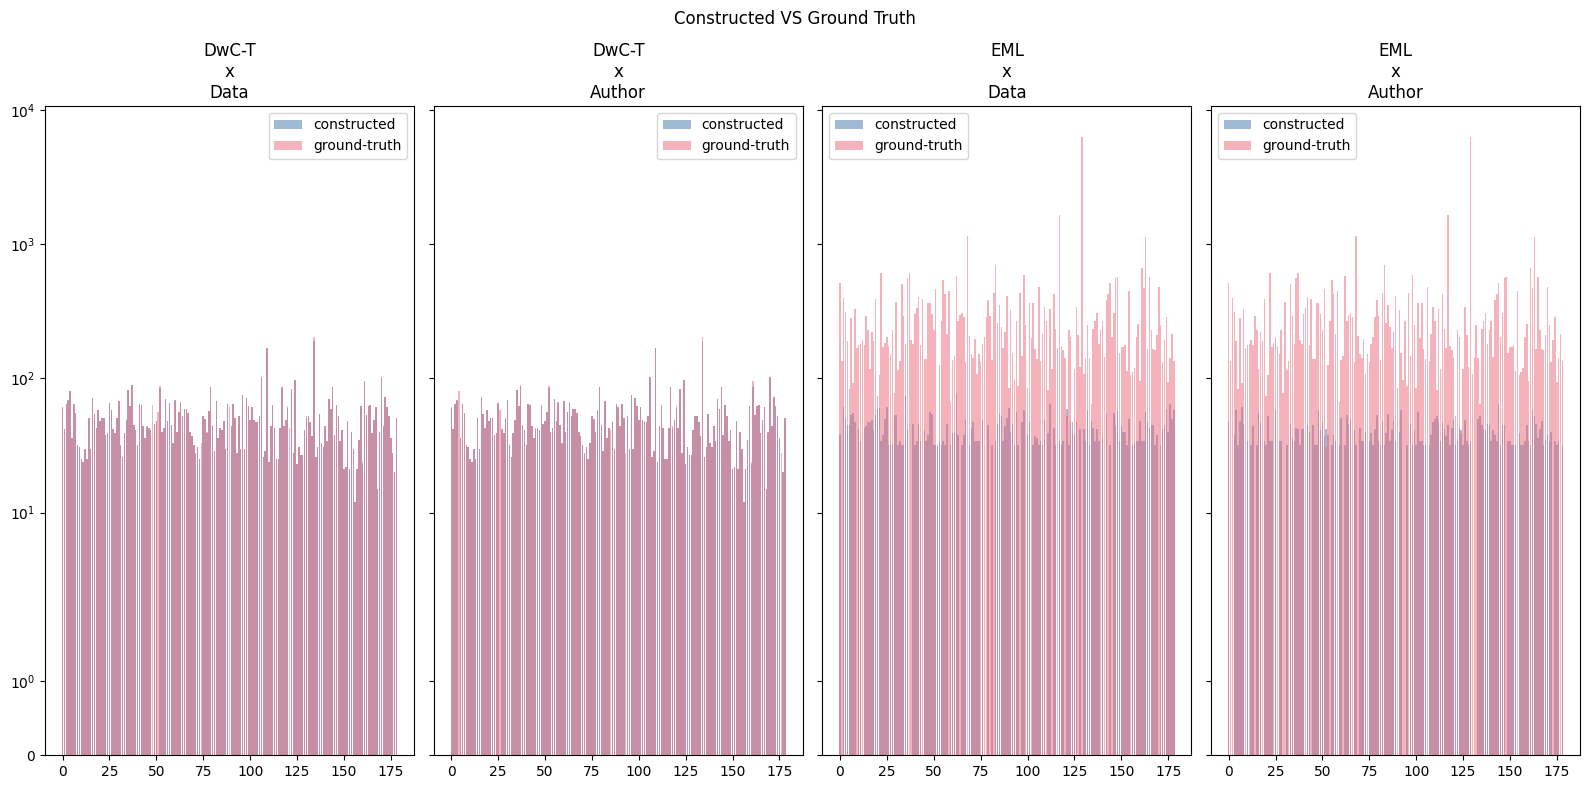

In [116]:
fig, axs = plt.subplots(1, len(cons_tree_info_groups.keys()), figsize=(16,8), sharey=True)

fig.suptitle("Constructed VS Ground Truth")
for (ax, (con_g, con_rs), (gt_g, gt_rs)) in zip(axs, cons_tree_info_groups.items(), gt_tree_info_groups.items()):
    ax.set_yscale("symlog")
    ax.set_title(fmt_result_group_title_multiline(con_g))
    ax.bar(con_rs["case_id"], con_rs["size"], alpha=0.5, label="constructed")
    ax.bar(gt_rs["case_id"], gt_rs["size"], alpha=0.5, label="ground-truth")
    ax.legend()

plt.tight_layout()

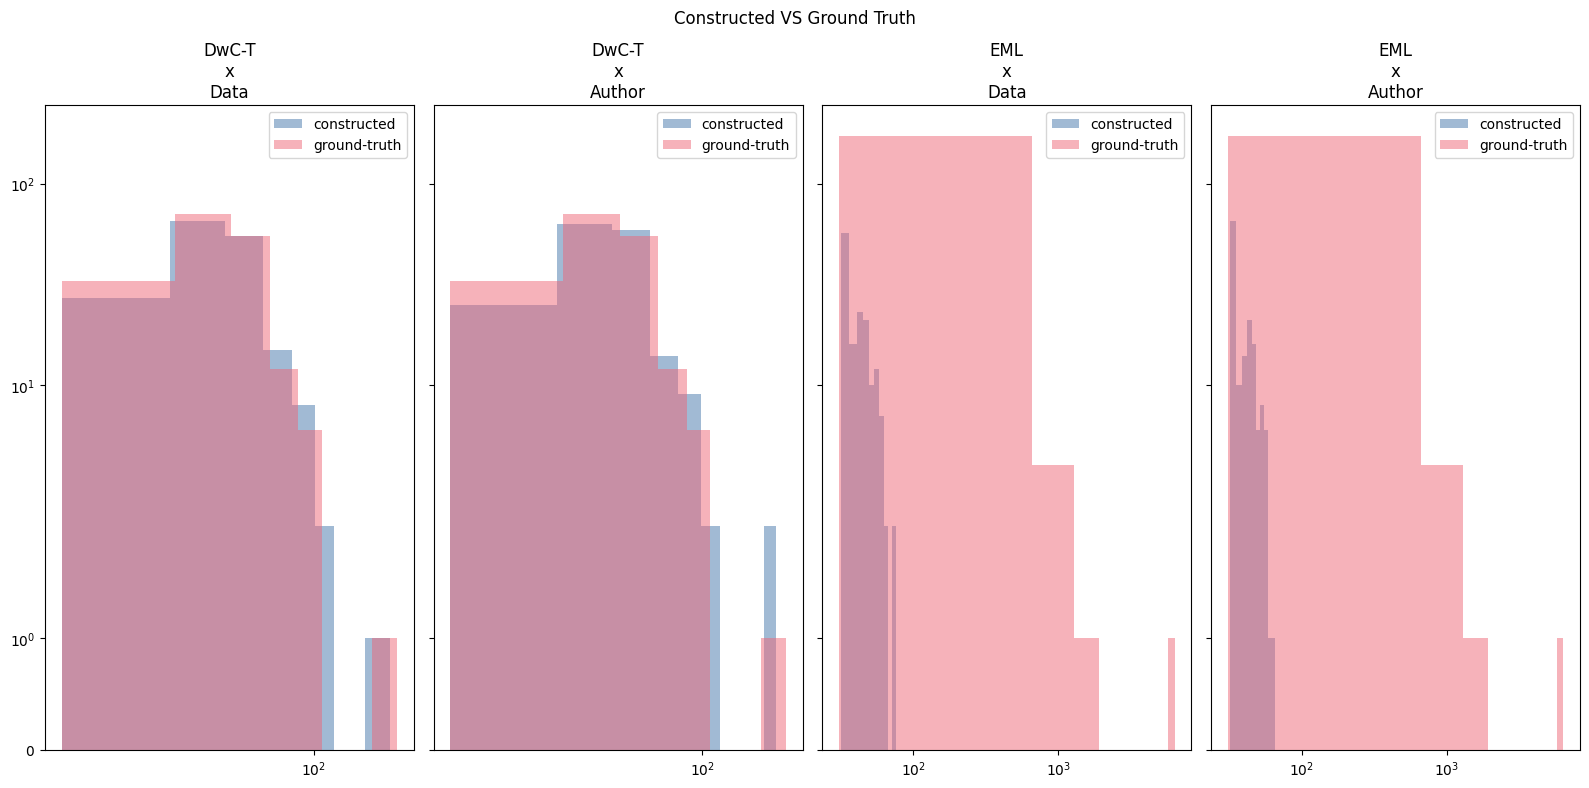

In [117]:
fig, axs = plt.subplots(1, len(cons_tree_info_groups.keys()), figsize=(16,8), sharey=True)

fig.suptitle("Constructed VS Ground Truth")
for (ax, (con_g, con_rs), (gt_g, gt_rs)) in zip(axs, cons_tree_info_groups.items(), gt_tree_info_groups.items()):
    ax.set_yscale("symlog")
    ax.set_xscale("symlog")
    ax.set_title(fmt_result_group_title_multiline(con_g))
    ax.hist(con_rs["size"], alpha=0.5, label="constructed")
    ax.hist(gt_rs["size"], alpha=0.5, label="ground-truth")
    ax.legend()

plt.tight_layout()

In [43]:
print("Constructed Metadata --> Trees")

for g,rs in cons_tree_info_groups.items():
    print(g)
    display(rs.describe(include="all"))
    display(rs.describe(include="all").to_latex())

Constructed Metadata --> Trees
DwC-T~Data


,case_id,size
count,174.000000,174.000000
mean,89.356322,49.149425
std,52.318163,22.960649
min,0.000000,12.000000
25%,43.250000,33.250000
50%,90.500000,45.000000
75%,134.750000,60.750000
max,178.000000,190.000000


'\\begin{tabular}{lrr}\n\\toprule\n & case_id & size \\\\\n\\midrule\ncount & 174.000000 & 174.000000 \\\\\nmean & 89.356322 & 49.149425 \\\\\nstd & 52.318163 & 22.960649 \\\\\nmin & 0.000000 & 12.000000 \\\\\n25% & 43.250000 & 33.250000 \\\\\n50% & 90.500000 & 45.000000 \\\\\n75% & 134.750000 & 60.750000 \\\\\nmax & 178.000000 & 190.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

DwC-T~Author


,case_id,size
count,174.000000,174.000000
mean,89.350575,49.206897
std,51.515395,22.552771
min,0.000000,12.000000
25%,45.250000,34.000000
50%,89.500000,45.500000
75%,133.750000,61.000000
max,178.000000,186.000000


...

,case_id,size
count,150.000000,150.000000
mean,88.686667,42.460000
std,53.070314,9.766145
min,0.000000,32.000000
25%,42.250000,34.000000
50%,88.500000,41.000000
75%,134.750000,48.000000
max,178.000000,76.000000


'\\begin{tabular}{lrr}\n\\toprule\n & case_id & size \\\\\n\\midrule\ncount & 150.000000 & 150.000000 \\\\\nmean & 88.686667 & 42.460000 \\\\\nstd & 53.070314 & 9.766145 \\\\\nmin & 0.000000 & 32.000000 \\\\\n25% & 42.250000 & 34.000000 \\\\\n50% & 88.500000 & 41.000000 \\\\\n75% & 134.750000 & 48.000000 \\\\\nmax & 178.000000 & 76.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

EML~Author


,case_id,size
count,148.000000,148.000000
mean,92.864865,40.094595
std,50.983477,7.939686
min,0.000000,32.000000
25%,49.750000,34.000000
50%,96.000000,38.000000
75%,137.250000,46.000000
max,178.000000,65.000000


'\\begin{tabular}{lrr}\n\\toprule\n & case_id & size \\\\\n\\midrule\ncount & 148.000000 & 148.000000 \\\\\nmean & 92.864865 & 40.094595 \\\\\nstd & 50.983477 & 7.939686 \\\\\nmin & 0.000000 & 32.000000 \\\\\n25% & 49.750000 & 34.000000 \\\\\n50% & 96.000000 & 38.000000 \\\\\n75% & 137.250000 & 46.000000 \\\\\nmax & 178.000000 & 65.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

In [44]:
print("Ground Truth Metadata --> Trees")

for g,rs in gt_tree_info_groups.items():
    print(g)
    display(rs.describe(include="all"))
    display(rs.describe(include="all").to_latex())

Ground Truth Metadata --> Trees
DwC-T~Data


,case_id,size
count,179.000000,179.000000
mean,89.000000,49.307263
std,51.816986,23.171091
min,0.000000,12.000000
25%,44.500000,33.500000
50%,89.000000,45.000000
75%,133.500000,61.000000
max,178.000000,202.000000


'\\begin{tabular}{lrr}\n\\toprule\n & case_id & size \\\\\n\\midrule\ncount & 179.000000 & 179.000000 \\\\\nmean & 89.000000 & 49.307263 \\\\\nstd & 51.816986 & 23.171091 \\\\\nmin & 0.000000 & 12.000000 \\\\\n25% & 44.500000 & 33.500000 \\\\\n50% & 89.000000 & 45.000000 \\\\\n75% & 133.500000 & 61.000000 \\\\\nmax & 178.000000 & 202.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

DwC-T~Author


,case_id,size
count,179.000000,179.000000
mean,89.000000,49.307263
std,51.816986,23.171091
min,0.000000,12.000000
25%,44.500000,33.500000
50%,89.000000,45.000000
75%,133.500000,61.000000
max,178.000000,202.000000


...

,case_id,size
count,179.000000,179.000000
mean,89.000000,299.810056
std,51.816986,494.601131
min,0.000000,31.000000
25%,44.500000,142.000000
50%,89.000000,206.000000
75%,133.500000,331.500000
max,178.000000,6326.000000


'\\begin{tabular}{lrr}\n\\toprule\n & case_id & size \\\\\n\\midrule\ncount & 179.000000 & 179.000000 \\\\\nmean & 89.000000 & 299.810056 \\\\\nstd & 51.816986 & 494.601131 \\\\\nmin & 0.000000 & 31.000000 \\\\\n25% & 44.500000 & 142.000000 \\\\\n50% & 89.000000 & 206.000000 \\\\\n75% & 133.500000 & 331.500000 \\\\\nmax & 178.000000 & 6326.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

EML~Author


,case_id,size
count,179.000000,179.000000
mean,89.000000,299.810056
std,51.816986,494.601131
min,0.000000,31.000000
25%,44.500000,142.000000
50%,89.000000,206.000000
75%,133.500000,331.500000
max,178.000000,6326.000000


'\\begin{tabular}{lrr}\n\\toprule\n & case_id & size \\\\\n\\midrule\ncount & 179.000000 & 179.000000 \\\\\nmean & 89.000000 & 299.810056 \\\\\nstd & 51.816986 & 494.601131 \\\\\nmin & 0.000000 & 31.000000 \\\\\n25% & 44.500000 & 142.000000 \\\\\n50% & 89.000000 & 206.000000 \\\\\n75% & 133.500000 & 331.500000 \\\\\nmax & 178.000000 & 6326.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

### Nodes 

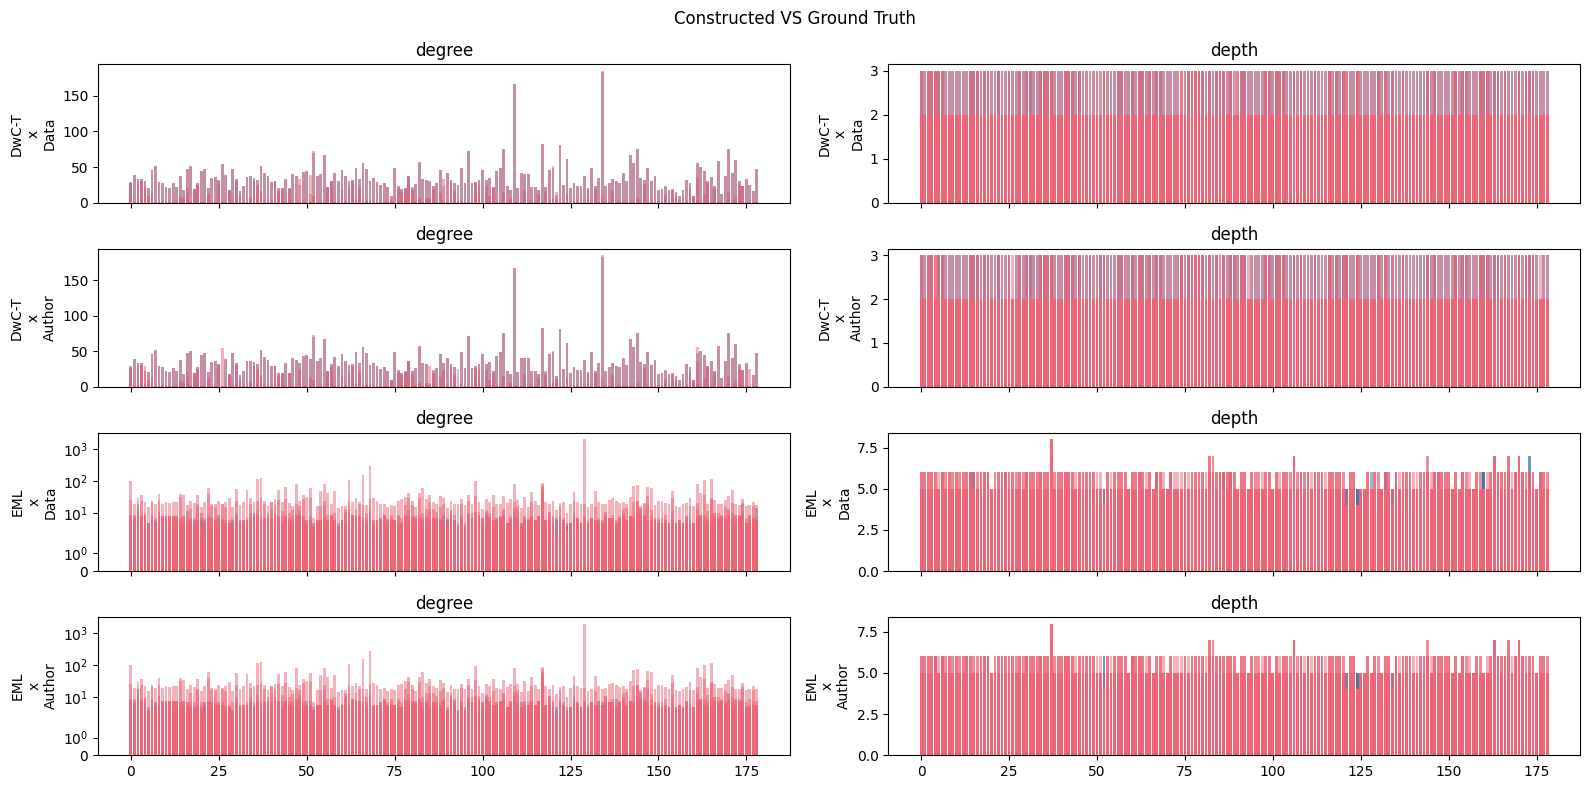

In [45]:
node_cols = ["degree", "depth"]
fig, axsm = plt.subplots(len(cons_tree_info_groups.keys()), len(node_cols), figsize=(16,8), sharex=True)

fig.suptitle("Constructed VS Ground Truth")
for (axs, (con_g, con_rs), (gt_g, gt_rs)) in zip(axsm, cons_node_info_groups.items(), gt_node_info_groups.items()):
    for (ax, col) in zip(axs, node_cols):
        ax.set_title(col)
        if (
            (max(con_rs[col]) - min(con_rs[col]) > 500)
            or (max(gt_rs[col]) - min(gt_rs[col]) > 500)
        ):
            ax.set_yscale("symlog")
            
        ax.set_ylabel(fmt_result_group_title_multiline(con_g))
        ax.bar(con_rs["case_id"], con_rs[col], alpha=0.5)
        ax.bar(gt_rs["case_id"], gt_rs[col], alpha=0.5)

plt.tight_layout()

In [46]:
print("Constructed Metadata --> Nodes")

for g,rs in cons_node_info_groups.items():
    print(g)
    display(rs.describe(include="all"))
    display(rs.describe(include="all").to_latex())

Constructed Metadata --> Nodes
DwC-T~Data


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,8552.000000,8552,8552.000000,8552.000000,8552,8552,8552,975,8552,8552
unique,NaN,8,NaN,NaN,2,2928,2,24,2,332
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},True,\n,False,.
freq,NaN,7310,NaN,NaN,7844,534,8018,267,8285,174
mean,88.918732,NaN,1.959308,0.979654,NaN,NaN,NaN,NaN,NaN,NaN
std,51.588900,NaN,0.377077,6.206240,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,43.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,91.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,134.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 8552.000000 & 8552 & 8552.000000 & 8552.000000 & 8552 & 8552 & 8552 & 975 & 8552 & 8552 \\\\\nunique & NaN & 8 & NaN & NaN & 2 & 2928 & 2 & 24 & 2 & 332 \\\\\ntop & NaN & {http://rs.tdwg.org/dwc/text/}field & NaN & NaN & True & {} & True & \n     & False & . \\\\\nfreq & NaN & 7310 & NaN & NaN & 7844 & 534 & 8018 & 267 & 8285 & 174 \\\\\nmean & 88.918732 & NaN & 1.959308 & 0.979654 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nstd & 51.588900 & NaN & 0.377077 & 6.206240 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n25% & 43.000000 & NaN & 2.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n50% & 91.000000 & NaN & 2.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n75% & 134.000000 & NaN & 2.000000 & 0.000000 & NaN & NaN & NaN 

DwC-T~Author


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,8562.000000,8562,8562.000000,8562.000000,8562,8562,8562,984,8562,8562
unique,NaN,8,NaN,NaN,2,2903,2,23,2,330
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},True,\n,False,.
freq,NaN,7308,NaN,NaN,7848,540,8022,270,8292,174
mean,89.333450,NaN,1.959355,0.979678,NaN,NaN,NaN,NaN,NaN,NaN
std,50.609223,NaN,0.377788,6.182620,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,46.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,91.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


...

,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,6369.000000,6369,6369.000000,6369.000000,6369,6369,6369,6238,6369,6369
unique,NaN,319,NaN,NaN,2,133,2,1246,2,706
top,NaN,para,NaN,NaN,False,{},False,\n,False,.
freq,NaN,697,NaN,NaN,3409,5740,5740,1258,3433,150
mean,88.133302,NaN,3.396452,0.976448,NaN,NaN,NaN,NaN,NaN,NaN
std,53.838807,NaN,1.229222,1.310859,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,40.000000,NaN,3.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,88.000000,NaN,4.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,135.000000,NaN,4.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 6369.000000 & 6369 & 6369.000000 & 6369.000000 & 6369 & 6369 & 6369 & 6238 & 6369 & 6369 \\\\\nunique & NaN & 319 & NaN & NaN & 2 & 133 & 2 & 1246 & 2 & 706 \\\\\ntop & NaN & para & NaN & NaN & False & {} & False & \n         & False & . \\\\\nfreq & NaN & 697 & NaN & NaN & 3409 & 5740 & 5740 & 1258 & 3433 & 150 \\\\\nmean & 88.133302 & NaN & 3.396452 & 0.976448 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nstd & 53.838807 & NaN & 1.229222 & 1.310859 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n25% & 40.000000 & NaN & 3.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n50% & 88.000000 & NaN & 4.000000 & 1.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n75% & 135.000000 & NaN & 4.000000 & 2.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\

EML~Author


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,5934.000000,5934,5934.000000,5934.000000,5934,5934,5934,5811,5934,5934
unique,NaN,297,NaN,NaN,2,133,2,1486,2,558
top,NaN,para,NaN,NaN,False,{},False,\n,False,.
freq,NaN,652,NaN,NaN,3194,5327,5327,1166,3202,148
mean,91.711156,NaN,3.337883,0.975059,NaN,NaN,NaN,NaN,NaN,NaN
std,50.854321,NaN,1.219922,1.282741,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,48.000000,NaN,3.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,92.000000,NaN,3.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,136.000000,NaN,4.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 5934.000000 & 5934 & 5934.000000 & 5934.000000 & 5934 & 5934 & 5934 & 5811 & 5934 & 5934 \\\\\nunique & NaN & 297 & NaN & NaN & 2 & 133 & 2 & 1486 & 2 & 558 \\\\\ntop & NaN & para & NaN & NaN & False & {} & False & \n         & False & . \\\\\nfreq & NaN & 652 & NaN & NaN & 3194 & 5327 & 5327 & 1166 & 3202 & 148 \\\\\nmean & 91.711156 & NaN & 3.337883 & 0.975059 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nstd & 50.854321 & NaN & 1.219922 & 1.282741 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n25% & 48.000000 & NaN & 3.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n50% & 92.000000 & NaN & 3.000000 & 1.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n75% & 136.000000 & NaN & 4.000000 & 2.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\

In [47]:
print("Ground Truth Metadata --> Nodes")

for g,rs in gt_node_info_groups.items():
    print(g)
    display(rs.describe(include="all"))
    display(rs.describe(include="all").to_latex())

Ground Truth Metadata --> Nodes
DwC-T~Data


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 8826.000000 & 8826 & 8826.000000 & 8826.000000 & 8826 & 8826 & 8826 & 1009 & 8826 & 8824 \\\\\nunique & NaN & 9 & NaN & NaN & 2 & 2895 & 2 & 32 & 2 & 345 \\\\\ntop & NaN & {http://rs.tdwg.org/dwc/text/}field & NaN & NaN & True & {} & True & \n     & False & . \\\\\nfreq & NaN & 7530 & NaN & NaN & 8089 & 563 & 8263 & 272 & 8545 & 179 \\\\\nmean & 88.565262 & NaN & 1.959438 & 0.979719 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nstd & 51.081215 & NaN & 0.377779 & 6.172877 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n25% & 45.000000 & NaN & 2.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n50% & 90.000000 & NaN & 2.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n75% & 133.000000 & NaN & 2.000000 & 0.000000 & NaN & NaN & NaN

DwC-T~Author


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


...

,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,53666.000000,53666,53666.000000,53666.000000,53666,53666,53666,53207,53666,53660
unique,NaN,122,NaN,NaN,2,661,2,15232,2,10769
top,NaN,taxonomicClassification,NaN,NaN,True,{},False,\n,True,.
freq,NaN,5259,NaN,NaN,35924,51180,51180,4070,35886,179
mean,94.440018,NaN,3.823166,0.996665,NaN,NaN,NaN,NaN,NaN,NaN
std,49.492698,NaN,1.006971,9.408301,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,52.000000,NaN,3.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,101.000000,NaN,4.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,129.000000,NaN,5.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 53666.000000 & 53666 & 53666.000000 & 53666.000000 & 53666 & 53666 & 53666 & 53207 & 53666 & 53660 \\\\\nunique & NaN & 122 & NaN & NaN & 2 & 661 & 2 & 15232 & 2 & 10769 \\\\\ntop & NaN & taxonomicClassification & NaN & NaN & True & {} & False & \n                     & True & . \\\\\nfreq & NaN & 5259 & NaN & NaN & 35924 & 51180 & 51180 & 4070 & 35886 & 179 \\\\\nmean & 94.440018 & NaN & 3.823166 & 0.996665 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nstd & 49.492698 & NaN & 1.006971 & 9.408301 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n25% & 52.000000 & NaN & 3.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n50% & 101.000000 & NaN & 4.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n75% & 129.000000 & NaN & 5.000000 &

EML~Author


,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,53666.000000,53666,53666.000000,53666.000000,53666,53666,53666,53207,53666,53660
unique,NaN,122,NaN,NaN,2,661,2,15232,2,10769
top,NaN,taxonomicClassification,NaN,NaN,True,{},False,\n,True,.
freq,NaN,5259,NaN,NaN,35924,51180,51180,4070,35886,179
mean,94.440018,NaN,3.823166,0.996665,NaN,NaN,NaN,NaN,NaN,NaN
std,49.492698,NaN,1.006971,9.408301,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,52.000000,NaN,3.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,101.000000,NaN,4.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,129.000000,NaN,5.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 53666.000000 & 53666 & 53666.000000 & 53666.000000 & 53666 & 53666 & 53666 & 53207 & 53666 & 53660 \\\\\nunique & NaN & 122 & NaN & NaN & 2 & 661 & 2 & 15232 & 2 & 10769 \\\\\ntop & NaN & taxonomicClassification & NaN & NaN & True & {} & False & \n                     & True & . \\\\\nfreq & NaN & 5259 & NaN & NaN & 35924 & 51180 & 51180 & 4070 & 35886 & 179 \\\\\nmean & 94.440018 & NaN & 3.823166 & 0.996665 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nstd & 49.492698 & NaN & 1.006971 & 9.408301 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n25% & 52.000000 & NaN & 3.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n50% & 101.000000 & NaN & 4.000000 & 0.000000 & NaN & NaN & NaN & NaN & NaN & NaN \\\\\n75% & 129.000000 & NaN & 5.000000 &

## Computing Pairwise Values

In [51]:
gt_node_info_groups["DwC-T~Author"].describe(include="all")

,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


In [63]:
gt_node_info_groups["DwC-T~Author"].groupby(by="tag").count().sort_values(by="case_id")

,case_id,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
tag,,,,,,,,,
<cyfunction Comment at 0x1128cbee0>,2,2,2,2,2,2,2,2,0
{http://rs.tdwg.org/dwc/text/}coreid,99,99,99,99,99,99,0,99,99
{http://rs.tdwg.org/dwc/text/}extension,100,100,100,100,100,100,97,100,100
{http://rs.tdwg.org/dwc/text/}archive,179,179,179,179,179,179,178,179,179
{http://rs.tdwg.org/dwc/text/}core,179,179,179,179,179,179,178,179,179
{http://rs.tdwg.org/dwc/text/}id,179,179,179,179,179,179,0,179,179
{http://rs.tdwg.org/dwc/text/}files,279,279,279,279,279,279,275,279,279
{http://rs.tdwg.org/dwc/text/}location,279,279,279,279,279,279,279,279,279
{http://rs.tdwg.org/dwc/text/}field,7530,7530,7530,7530,7530,7530,0,7530,7530


In [64]:
cons_node_info_groups["DwC-T~Author"].groupby(by="tag").count().sort_values(by="case_id")

,case_id,depth,degree,is_leaf,attributes,has_attributes,text,has_text,path
tag,,,,,,,,,
{http://rs.tdwg.org/dwc/text/}coreid,96,96,96,96,96,96,0,96,96
{http://rs.tdwg.org/dwc/text/}extension,96,96,96,96,96,96,96,96,96
{http://rs.tdwg.org/dwc/text/}archive,174,174,174,174,174,174,174,174,174
{http://rs.tdwg.org/dwc/text/}core,174,174,174,174,174,174,174,174,174
{http://rs.tdwg.org/dwc/text/}id,174,174,174,174,174,174,0,174,174
{http://rs.tdwg.org/dwc/text/}files,270,270,270,270,270,270,270,270,270
{http://rs.tdwg.org/dwc/text/}location,270,270,270,270,270,270,270,270,270
{http://rs.tdwg.org/dwc/text/}field,7308,7308,7308,7308,7308,7308,0,7308,7308


In [65]:
gt_node_info_groups["DwC-T~Author"].groupby(by="path").count().sort_values(by="case_id")

,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text
path,,,,,,,,,
{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[53],1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[32],1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[31],1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[30],1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[29],1,1,1,1,1,1,1,0,1
...,...,...,...,...,...,...,...,...,...
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],179,179,179,179,179,179,179,0,179
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],179,179,179,179,179,179,179,0,179
{http://rs.tdwg.org/dwc/text/}core,179,179,179,179,179,179,179,178,179


In [66]:
cons_node_info_groups["DwC-T~Author"].groupby(by="path").count().sort_values(by="case_id")

,case_id,tag,depth,degree,is_leaf,attributes,has_attributes,text,has_text
path,,,,,,,,,
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[176],1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}field[20],1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}field[19],1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}field[18],1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[166],1,1,1,1,1,1,1,0,1
...,...,...,...,...,...,...,...,...,...
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],174,174,174,174,174,174,174,0,174
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],174,174,174,174,174,174,174,0,174
{http://rs.tdwg.org/dwc/text/}core,174,174,174,174,174,174,174,174,174


### Compute JIs

In [354]:
def jaccard_index(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> float:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (len(set.intersection(cons_data,gt_data))/len(set.union(cons_data,gt_data)))

def intersection_size(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> float:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (len(set.intersection(cons_data,gt_data)))

def union_size(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> float:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (len(set.union(cons_data,gt_data)))

In [70]:
result_groups[g]["constructed.xml_tree.characteristics"]

0      {'value': {'size': 61, '_nodes': [{'tag': '{ht...
1      {'value': {'size': 42, '_nodes': [{'tag': '{ht...
2      {'value': {'size': 25, '_nodes': [{'tag': '{ht...
3      {'value': {'size': 49, '_nodes': [{'tag': '{ht...
4      {'value': {'size': 61, '_nodes': [{'tag': '{ht...
                             ...                        
174    {'value': {'size': 30, '_nodes': [{'tag': '{ht...
175    {'value': {'size': 75, '_nodes': [{'tag': '{ht...
176    {'value': {'size': 30, '_nodes': [{'tag': '{ht...
177    {'value': {'size': 72, '_nodes': [{'tag': '{ht...
178    {'value': {'size': 62, '_nodes': [{'tag': '{ht...
Name: constructed.xml_tree.characteristics, Length: 179, dtype: object

In [360]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.tag_intersection_size"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            intersection_size("tag", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
    result_groups[g]["cons_vs_gt_tree.tag_union_size"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            union_size("tag", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
    result_groups[g]["cons_vs_gt_tree.tag_jaccard_index"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            jaccard_index("tag", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
g, result_groups[g]["cons_vs_gt_tree.tag_jaccard_index"]

('EML~Author',
 0      0.282353
 1           NaN
 2      0.237500
 3      0.203125
 4      0.255556
          ...   
 174    0.184615
 175         NaN
 176    0.197368
 177    0.275000
 178    0.244444
 Name: cons_vs_gt_tree.tag_jaccard_index, Length: 179, dtype: float64)

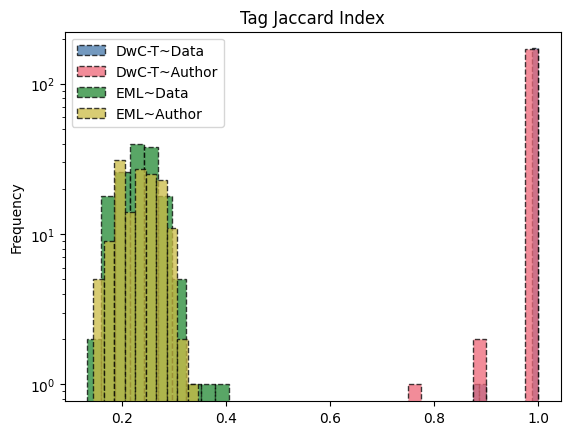

In [374]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.tag_jaccard_index"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Tag Jaccard Index")

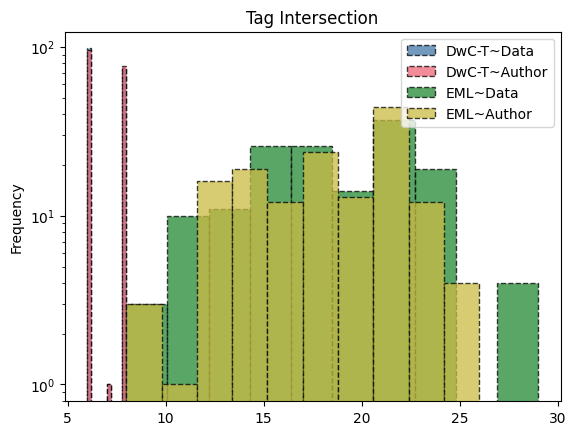

In [373]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.tag_intersection_size"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Tag Intersection")

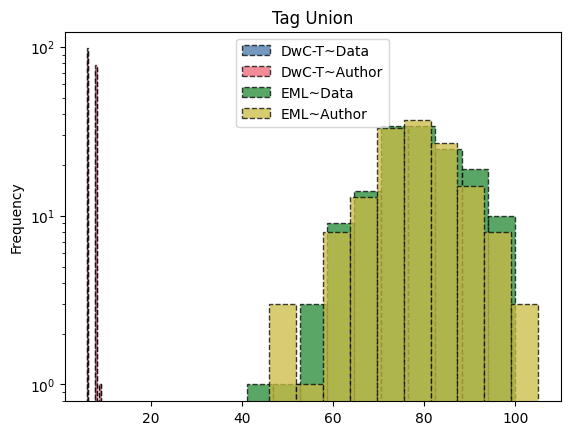

In [372]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.tag_union_size"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Tag Union")

In [364]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.path_intersection_size"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            intersection_size("path", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
    result_groups[g]["cons_vs_gt_tree.path_union_size"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            union_size("path", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
    result_groups[g]["cons_vs_gt_tree.path_jaccard_index"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            jaccard_index("path", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
g, result_groups[g]["cons_vs_gt_tree.path_jaccard_index"]

('EML~Author',
 0      0.058824
 1           NaN
 2      0.111111
 3      0.125000
 4      0.065657
          ...   
 174    0.081081
 175         NaN
 176    0.054645
 177    0.033113
 178    0.077491
 Name: cons_vs_gt_tree.path_jaccard_index, Length: 179, dtype: float64)

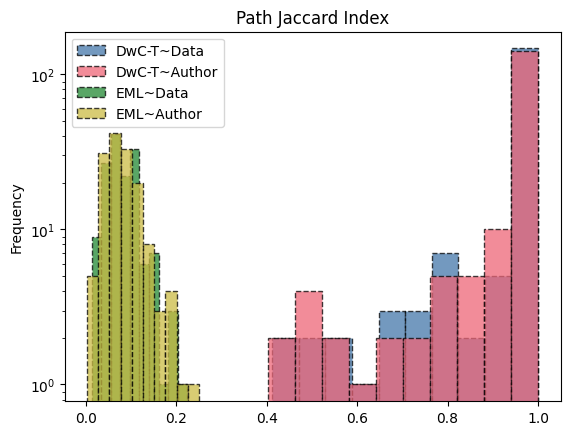

In [371]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.path_jaccard_index"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Path Jaccard Index")

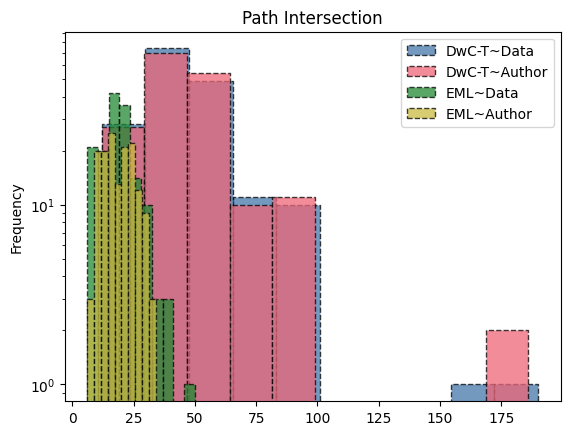

In [370]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.path_intersection_size"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Path Intersection")

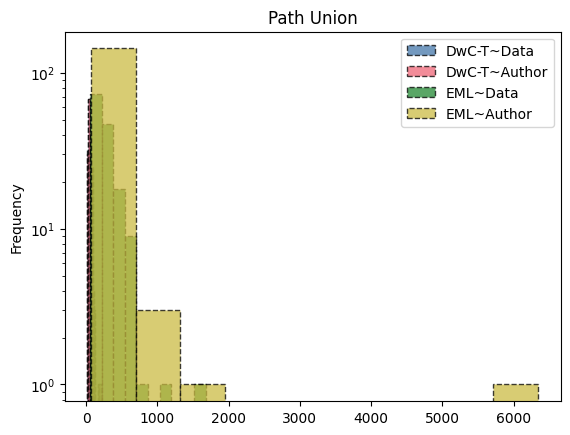

In [369]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.path_union_size"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Path Union")

In [108]:
for g, rs in result_groups.items():    
    print("----")
    print(g)
    print("Tag JI:\t\t", stats.normaltest(with_ok_constructed_trees(rs)["cons_vs_gt_tree.tag_jaccard_index"]))
    print("(LogN):\t\t", stats.normaltest(np.log(with_ok_constructed_trees(rs)["cons_vs_gt_tree.tag_jaccard_index"])))
    print("Path JI:\t", stats.normaltest(with_ok_constructed_trees(rs)["cons_vs_gt_tree.path_jaccard_index"]))
    print("(LogN):\t\t", stats.normaltest(np.log(with_ok_constructed_trees(rs)["cons_vs_gt_tree.path_jaccard_index"])))

----
DwC-T~Data
Tag JI:		 NormaltestResult(statistic=np.float64(315.0412329982547), pvalue=np.float64(3.887455838081462e-69))
(LogN):		 NormaltestResult(statistic=np.float64(315.18451768153244), pvalue=np.float64(3.618691787387586e-69))
Path JI:	 NormaltestResult(statistic=np.float64(131.62678423756907), pvalue=np.float64(2.615814648442218e-29))
(LogN):		 NormaltestResult(statistic=np.float64(152.86861348779337), pvalue=np.float64(6.3826694433743515e-34))
----
DwC-T~Author
Tag JI:		 NormaltestResult(statistic=np.float64(312.92353180132943), pvalue=np.float64(1.1207750141605293e-68))
(LogN):		 NormaltestResult(statistic=np.float64(319.0433757247308), pvalue=np.float64(5.255465839027439e-70))
Path JI:	 NormaltestResult(statistic=np.float64(122.37422463134394), pvalue=np.float64(2.6716204412857325e-27))
(LogN):		 NormaltestResult(statistic=np.float64(140.91977201486793), pvalue=np.float64(2.5099224980133217e-31))
----
EML~Data
Tag JI:		 NormaltestResult(statistic=np.float64(15.73379996063

### Compute Tree Sim (APTED)

In [119]:
@do_on_value
@do_or_error
def xml_to_apted_tree(tree):
    if hasattr(tree, "getroot"):
        return convert_xml_to_apted(tree.getroot())
    return convert_xml_to_apted(tree)

def convert_xml_to_apted(root):
    tag = root.tag
    
    if root.attrib:
        attr_parts = [f"{{key__{k}:{{hidden_value}}}}" for k, _v in sorted(root.attrib.items())]
        node_label = f"{tag}:{':'.join(attr_parts)}"
    else:
        node_label = tag
    
    apted_children = [convert_xml_to_apted(child) for child in root]    
    return apted.helpers.Tree(node_label, *apted_children)

In [153]:
@do_on_value
def apted_tree_size(tree):
    return _apted_tree_size(tree)

def _apted_tree_size(tree):
    return 1 + sum(_apted_tree_size(child) for child in tree.children)

def normalise_apted_edit_distance(raw_distance, tree1, tree2):
    max_dist = _apted_tree_size(tree1) + _apted_tree_size(tree2)
    return raw_distance / max_dist if max_dist > 0 else 0

In [461]:
def get_error_breakdown(apted_edit_mapping):
    breakdown = {
        "deletions": [],    # In Tree 1, but not in Tree 2
        "insertions": [],   # In Tree 2, but not in Tree 1
        "renames": [],      # In both, but labels/attributes differ
        "matches": []       # Identical nodes
    }
    
    for node1, node2 in apted_edit_mapping:
        if node1 is None:
            # Node exists only in generated (Tree 2) -> Hallucination
            breakdown["insertions"].append(node2.name)
        elif node2 is None:
            # Node exists only in ground truth (Tree 1) -> Omission
            breakdown["deletions"].append(node1.name)
        else:
            # Both exist; check if the label (tag + attributes) is the same
            if node1.name != node2.name:
                breakdown["renames"].append((node1.name, node2.name))
            else:
                breakdown["matches"].append(node1.name)

    counts = {f"{key}_count": len(vals) for key, vals in breakdown.items()}
    total = sum(v for _, v in counts.items())
    return {
        **breakdown, 
        **counts,
        "total": total,
        "replacements_count": total - counts["matches_count"],
    }

In [462]:
for g, rs in result_groups.items():
    result_groups[g]["constructed.xml_tree.apted_format"] = with_ok_constructed_trees(rs)["constructed.xml_tree"].apply(xml_to_apted_tree)
    result_groups[g]["ground_truth.xml_tree.apted_format"] = with_ok_constructed_trees(rs)["ground_truth.xml_tree"].apply(xml_to_apted_tree)

In [463]:
(
    with_ok_constructed_trees(rs)["ground_truth.xml_tree.apted_format"].apply(apted_tree_size), 
    with_ok_constructed_trees(rs)["ground_truth.xml_tree.characteristics"].apply(lambda x: x["value"]["size"])
)

(0      511
 2      176
 3       85
 4      366
 5      201
       ... 
 171    156
 174     88
 176    147
 177    592
 178    251
 Name: ground_truth.xml_tree.apted_format, Length: 148, dtype: int64,
 0      511
 2      176
 3       85
 4      366
 5      201
       ... 
 171    156
 174     88
 176    147
 177    592
 178    251
 Name: ground_truth.xml_tree.characteristics, Length: 148, dtype: int64)

In [464]:
%%time
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance"] = with_ok_constructed_trees(rs).apply(
        lambda x: apted.APTED(x["constructed.xml_tree.apted_format"]["value"], x["ground_truth.xml_tree.apted_format"]["value"]), 
        axis=1,
    ).apply(
        lambda a: a.compute_edit_distance()
    )

CPU times: user 16.3 s, sys: 75.4 ms, total: 16.4 s
Wall time: 16.5 s


In [465]:
result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance"]

0      479.0
1        NaN
2      164.0
3       74.0
4      343.0
       ...  
174     76.0
175      NaN
176    134.0
177    569.0
178    232.0
Name: cons_vs_gt_tree.apted_tree_edit_distance, Length: 179, dtype: float64

In [466]:
%%time
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance.normalised"] = with_ok_constructed_trees(rs).apply(
        lambda x: normalise_apted_edit_distance(x["cons_vs_gt_tree.apted_tree_edit_distance"], x["constructed.xml_tree.apted_format"]["value"], x["ground_truth.xml_tree.apted_format"]["value"]), 
        axis=1,
    )
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance.sim_score"] = 1 - with_ok_constructed_trees(result_groups[g])["cons_vs_gt_tree.apted_tree_edit_distance.normalised"]

CPU times: user 27.2 ms, sys: 2.24 ms, total: 29.4 ms
Wall time: 27.8 ms


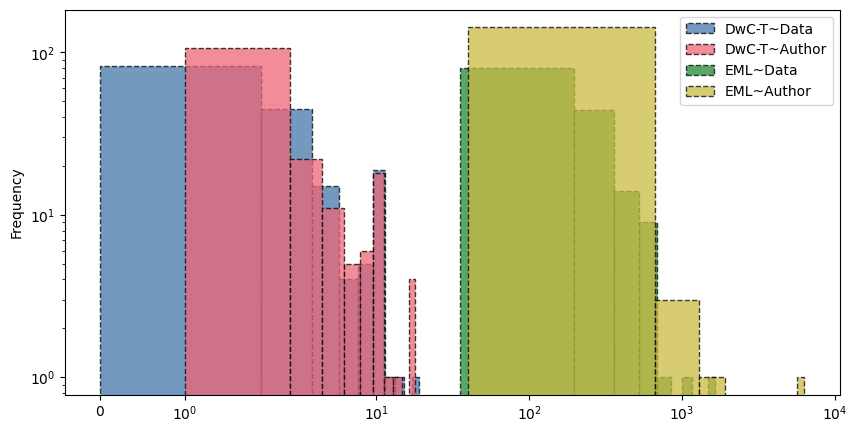

In [467]:
fig, ax = plt.subplots(figsize=(10,5))

ax.set_xscale("symlog")
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, ax=ax, label=g)

plt.show()

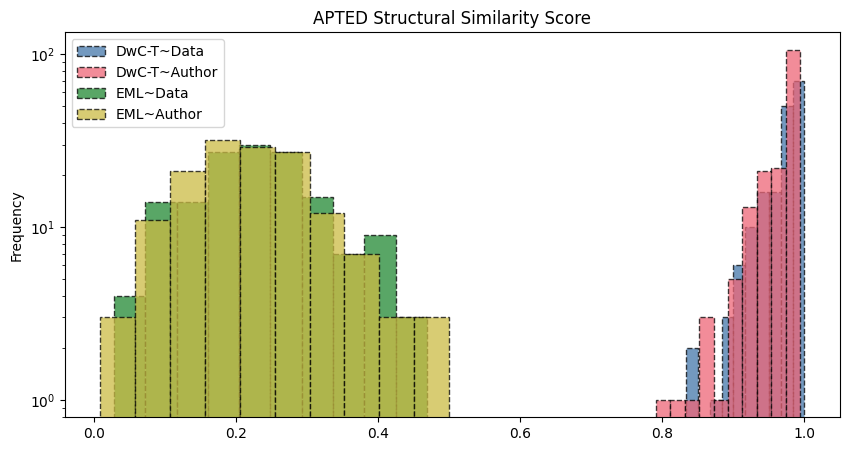

In [468]:
fig, ax = plt.subplots(figsize=(10,5))

ax.set_title("APTED Structural Similarity Score")
# ax.set_xscale("symlog")
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance.sim_score"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, ax=ax, label=g)

plt.show()

In [469]:
for g, rs in result_groups.items():    
    print("----")
    print(g)
    print("APTED:\t\t", stats.normaltest(with_ok_constructed_trees(rs)["cons_vs_gt_tree.apted_tree_edit_distance.sim_score"]))
    print("(LogN):\t\t", stats.normaltest(np.log(with_ok_constructed_trees(rs)["cons_vs_gt_tree.apted_tree_edit_distance.sim_score"])))

----
DwC-T~Data
APTED:		 NormaltestResult(statistic=np.float64(77.66299240596564), pvalue=np.float64(1.3667701175093959e-17))
(LogN):		 NormaltestResult(statistic=np.float64(84.61479710069335), pvalue=np.float64(4.227954120243065e-19))
----
DwC-T~Author
APTED:		 NormaltestResult(statistic=np.float64(101.9286818901659), pvalue=np.float64(7.353057357785612e-23))
(LogN):		 NormaltestResult(statistic=np.float64(112.01230595060193), pvalue=np.float64(4.751566482887408e-25))
----
EML~Data
APTED:		 NormaltestResult(statistic=np.float64(2.691908376516904), pvalue=np.float64(0.260291222499635))
(LogN):		 NormaltestResult(statistic=np.float64(32.32784465636306), pvalue=np.float64(9.552075070614842e-08))
----
EML~Author
APTED:		 NormaltestResult(statistic=np.float64(3.5236131943040427), pvalue=np.float64(0.1717343286524855))
(LogN):		 NormaltestResult(statistic=np.float64(86.84843494684779), pvalue=np.float64(1.3838912720653072e-19))


In [470]:
%%time
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_mapping"] = with_ok_constructed_trees(rs).apply(
        lambda x: apted.APTED(x["constructed.xml_tree.apted_format"]["value"], x["ground_truth.xml_tree.apted_format"]["value"]), 
        axis=1,
    ).apply(
        lambda a: a.compute_edit_mapping()
    )

CPU times: user 17.5 s, sys: 66 ms, total: 17.6 s
Wall time: 17.6 s


In [471]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"] = with_ok_constructed_trees(rs)["cons_vs_gt_tree.apted_tree_edit_mapping"].apply(get_error_breakdown)
g, result_groups[g]["cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"] 

('EML~Author',
 0      {'deletions': ['project', 'instrumentation', '...
 1                                                    NaN
 2      {'deletions': ['project', 'methods'], 'inserti...
 3      {'deletions': ['project', 'title', 'qualityCon...
 4      {'deletions': ['project', 'methods', 'descript...
                              ...                        
 174    {'deletions': ['project', 'methods'], 'inserti...
 175                                                  NaN
 176    {'deletions': ['project', 'title', 'methods', ...
 177    {'deletions': ['project', 'instrumentation', '...
 178    {'deletions': ['project', 'instrumentation', '...
 Name: cons_vs_gt_tree.apted_tree_edit_mapping_breakdown, Length: 179, dtype: object)

In [472]:
tree_edit_breakdown_groups = {}

for g, rs in result_groups.items():
    tree_edit_breakdown_groups[g] = pd.DataFrame.from_records(with_ok_constructed_trees(rs)["cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"])
    tree_edit_breakdown_groups[g]["case_id"] = with_ok_constructed_trees(rs)["case_id"]
g, tree_edit_breakdown_groups[g].describe()

('EML~Author',
        deletions_count  insertions_count  renames_count  matches_count  \
 count       148.000000        148.000000     148.000000     148.000000   
 mean          5.141892        274.790541      15.229730      19.722973   
 std           2.955475        540.316816       8.706159       6.051728   
 min           2.000000          4.000000       2.000000       6.000000   
 25%           3.000000        109.500000       8.000000      15.000000   
 50%           4.000000        177.500000      16.000000      18.000000   
 75%           7.000000        287.500000      22.000000      25.000000   
 max          16.000000       6295.000000      38.000000      37.000000   
 
              total  replacements_count     case_id  
 count   148.000000          148.000000  123.000000  
 mean    314.885135          295.162162   95.268293  
 std     540.173473          539.508646   55.125650  
 min      46.000000           40.000000    0.000000  
 25%     148.750000          130.00000

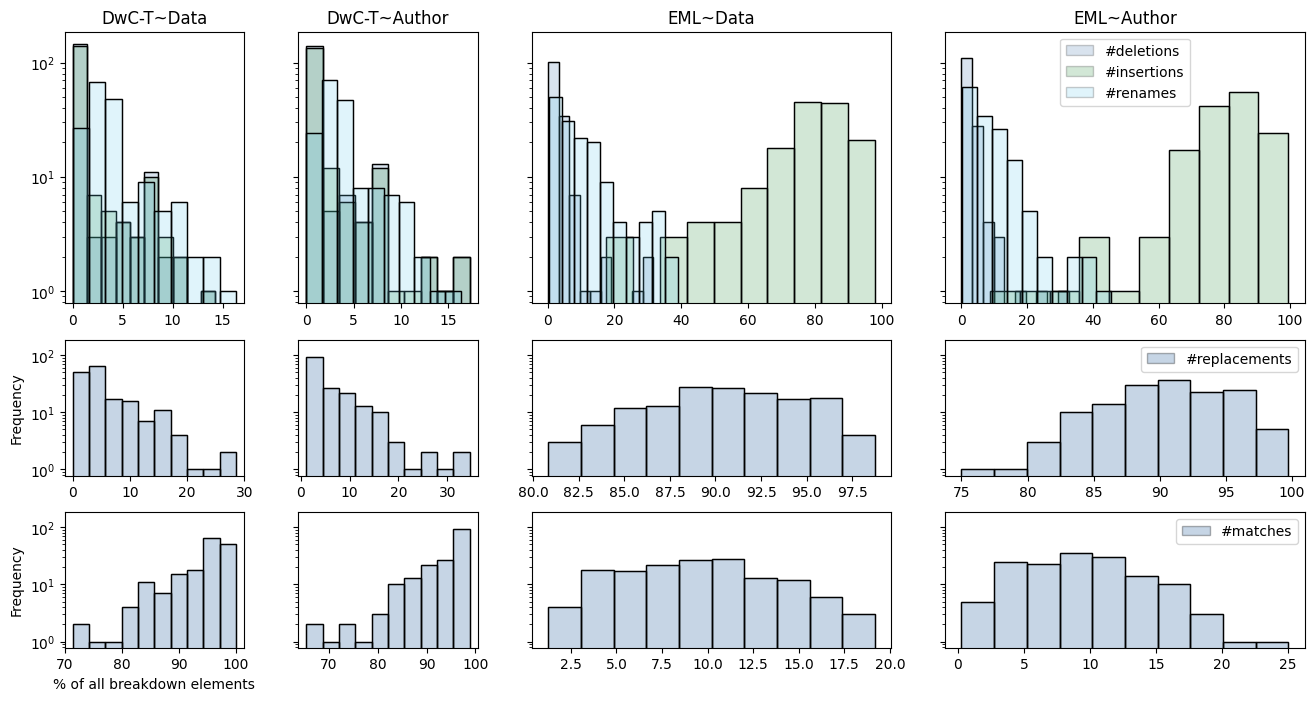

In [492]:
fig, axs = plt.subplots(3, len(tree_edit_breakdown_groups.keys()), figsize=(16,8), sharey=True, height_ratios=(2,1,1), width_ratios=(1,1,2,2))

matches_c = "matches_count"
replacements_c = "replacements_count"
columns = [
    "deletions_count", 
    "insertions_count", 
    "renames_count", 
    # matches_c
]

for i, (ax_t, (g, rs)) in enumerate(zip(axs[0], tree_edit_breakdown_groups.items())):
    # ax_t.set_xscale("symlog")
    ax_t.set_title(g)
    for j, (c, ls) in enumerate(zip(columns, ["--", "-.", ":"])):
        ((rs[c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, alpha=0.2, edgecolor="k", log=True, ax=ax_t, label=("#" + c.split("_")[0]))
        ((rs[c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, facecolor="#ffffff00", edgecolor="k", log=True, ax=ax_t)
    ax_t.legend() if i == 3 else ...
    ax_t.set_ylabel("")

for i, (ax_m, (g, rs)) in enumerate(zip(axs[1], tree_edit_breakdown_groups.items())):
    ((rs[replacements_c] / rs["total"]) * 100).plot.hist(alpha=0.3, ls="-", lw=1, edgecolor="k", log=True, ax=ax_m, label="#" + replacements_c.split("_")[0])
    ((rs[replacements_c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, facecolor="#ffffff00", edgecolor="k", log=True, ax=ax_m)
    ax_m.legend() if i == 3 else ...

for i, (ax_b, (g, rs)) in enumerate(zip(axs[2], tree_edit_breakdown_groups.items())):
    ((rs[matches_c] / rs["total"]) * 100).plot.hist(alpha=0.3, ls="-", lw=1, edgecolor="k", log=True, ax=ax_b, label="#" + matches_c.split("_")[0])
    ((rs[matches_c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, facecolor="#ffffff00", edgecolor="k", log=True, ax=ax_b)
    ax_b.set_xlabel("% of all breakdown elements") if i == 0 else ...
    ax_b.legend() if i == 3 else ...

plt.show()

In [474]:
matches_c = "matches_count"
columns = [
    "deletions_count", 
    "insertions_count", 
    "renames_count", 
    matches_c
]

for c in columns:
    for g, rs in tree_edit_breakdown_groups.items():    
        print(f"---- {c} ----")
        print(g)
        print(f"{c}:\t", stats.normaltest(rs[c]))
        print("(LogN1P):\t", stats.normaltest(np.log1p(rs[c])))

---- deletions_count ----
DwC-T~Data
deletions_count:	 NormaltestResult(statistic=np.float64(79.14247900153), pvalue=np.float64(6.522724606800856e-18))
(LogN1P):	 NormaltestResult(statistic=np.float64(67.27282061684934), pvalue=np.float64(2.465429635150809e-15))
---- deletions_count ----
DwC-T~Author
deletions_count:	 NormaltestResult(statistic=np.float64(94.01209849147097), pvalue=np.float64(3.850633603664285e-21))
(LogN1P):	 NormaltestResult(statistic=np.float64(53.15807092682606), pvalue=np.float64(2.863331057521004e-12))
---- deletions_count ----
EML~Data
deletions_count:	 NormaltestResult(statistic=np.float64(52.52560233300562), pvalue=np.float64(3.928351803244184e-12))
(LogN1P):	 NormaltestResult(statistic=np.float64(3.1513306989673864), pvalue=np.float64(0.2068698661227753))
---- deletions_count ----
EML~Author
deletions_count:	 NormaltestResult(statistic=np.float64(31.62829087711292), pvalue=np.float64(1.3552015821782305e-07))
(LogN1P):	 NormaltestResult(statistic=np.float64(10

### Reporting Pairwise Structural Similiarity

#### Top-K Common Tags and Paths

In [475]:
all_tags_groups = {}

for g in cons_node_info_groups.keys():
    all_tags = sorted(list(set.union(
        set(cons_node_info_groups[g]["tag"].apply(str).unique().tolist()),
        set(gt_node_info_groups[g]["tag"].apply(str).unique().tolist()),
    )))
    all_tags_groups[g] = {
        "values": all_tags, 
        "mapper_key_to_idx": {t: i for i, t in enumerate(all_tags)},
        "mapper_idx_to_key": {i: t for i, t in enumerate(all_tags)},
    }

In [476]:
all_paths_groups = {}

for g in cons_node_info_groups.keys():
    all_paths = sorted(list(set.union(
        set(cons_node_info_groups[g]["path"].apply(str).unique().tolist()),
        set(gt_node_info_groups[g]["path"].apply(str).unique().tolist()),
    )))
    all_paths_groups[g] = {
        "values": all_paths, 
        "mapper_key_to_idx": {t: i for i, t in enumerate(all_tags)},
        "mapper_idx_to_key": {i: t for i, t in enumerate(all_tags)},
    }

In [477]:
TOP_K = 11

cons_top_k=tag
field        7310
files         267
location      267
archive       174
core          174
id            174
extension      93
coreid         93
Name: count, dtype: int64
gt_top_k=tag
field           7530
files            279
location         279
archive          179
core             179
id               179
extension        100
coreid            99
<!-- ... -->       2
Name: count, dtype: int64
cons_top_k=tag
field        7308
files         270
location      270
archive       174
core          174
id            174
extension      96
coreid         96
Name: count, dtype: int64
gt_top_k=tag
field           7530
files            279
location         279
archive          179
core             179
id               179
extension        100
coreid            99
<!-- ... -->       2
Name: count, dtype: int64
cons_top_k=tag
para               697
description        483
individualName     388
surName            388
title              301
descriptor         278
descriptorValue    27

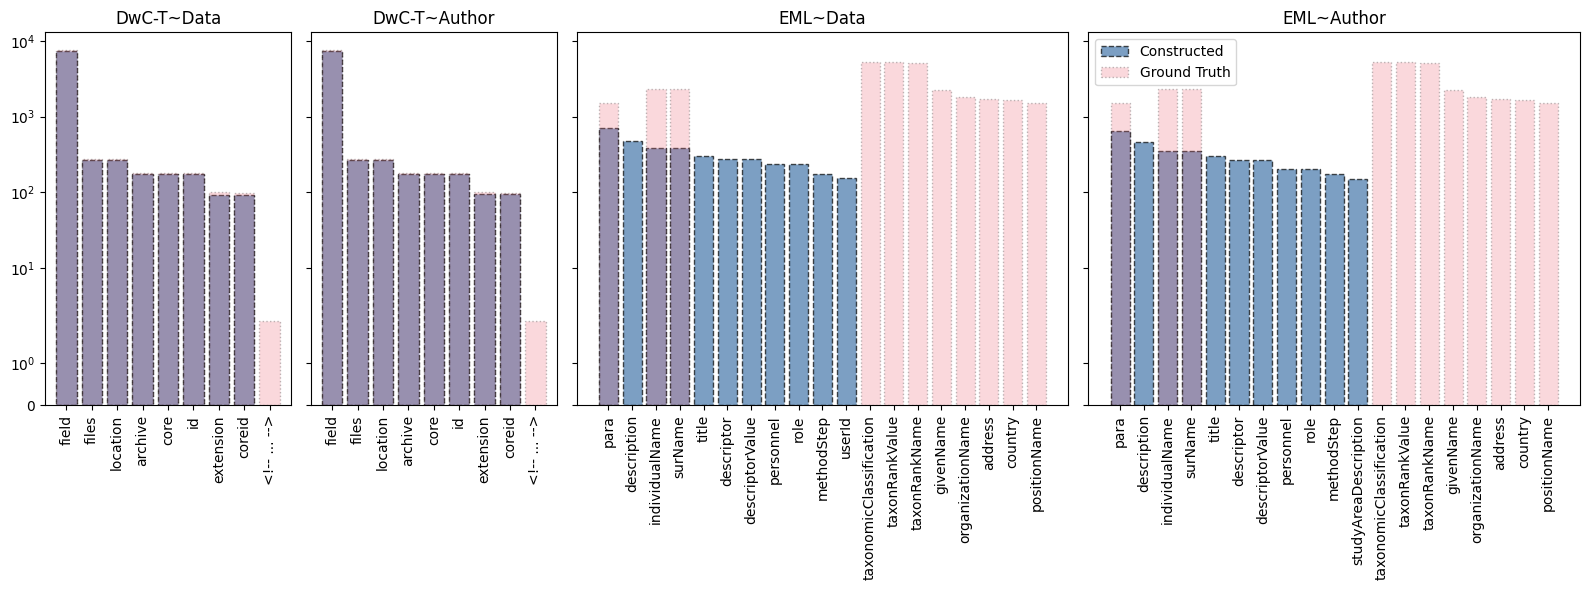

In [478]:
fig,axs = plt.subplots(1, 4, figsize=(16,6), sharey=True, width_ratios=(1,1,2,2))

for i, (ax, (g, cons_rs), (_, gt_rs)) in enumerate(zip(axs, cons_node_info_groups.items(), gt_node_info_groups.items())):
    cons_top_k = (
        cons_rs["tag"]
            # .apply(lambda t: all_tags_groups[g]["mapper_key_to_idx"][str(t)])
            .apply(lambda t: "<!-- ... -->" if (st:=str(t)) and "Comment" in st else st.split("}")[-1])
            .value_counts().nlargest(TOP_K)
    )
    gt_top_k = (
        gt_rs["tag"]
            # .apply(lambda t: all_tags_groups[g]["mapper_key_to_idx"][str(t)])
            .apply(lambda t: "<!-- ... -->" if (st:=str(t)) and "Comment" in st else st.split("}")[-1])
            .value_counts().nlargest(TOP_K)
    )

    print(f"{cons_top_k=}")
    print(f"{gt_top_k=}")

    ax.set_title(g)
    ax.set_yscale("symlog")
    ax.tick_params("x", rotation=90)
    
    ax.bar(cons_top_k.index, cons_top_k, alpha=0.7, label="Constructed", ls="--", lw=1, edgecolor="black")
    ax.bar(gt_top_k.index, gt_top_k, alpha=0.25, label="Ground Truth", ls=":", lw=1, edgecolor="black")
    
    ax.legend() if i == 3 else ...
    
plt.tight_layout()
plt.show()

cons_top_k=path
core                                               174
core $\rightarrow$ files                           174
core $\rightarrow$ files $\rightarrow$ location    174
core $\rightarrow$ id                              174
core $\rightarrow$ field[1]                        174
core $\rightarrow$ field[2]                        174
core $\rightarrow$ field[3]                        174
core $\rightarrow$ field[4]                        174
core $\rightarrow$ field[5]                        174
core $\rightarrow$ field[6]                        174
core $\rightarrow$ field[7]                        174
Name: count, dtype: int64
gt_top_k=path
core                                               179
core $\rightarrow$ files                           179
core $\rightarrow$ files $\rightarrow$ location    179
core $\rightarrow$ id                              179
core $\rightarrow$ field[1]                        179
core $\rightarrow$ field[2]                        179
core $\ri

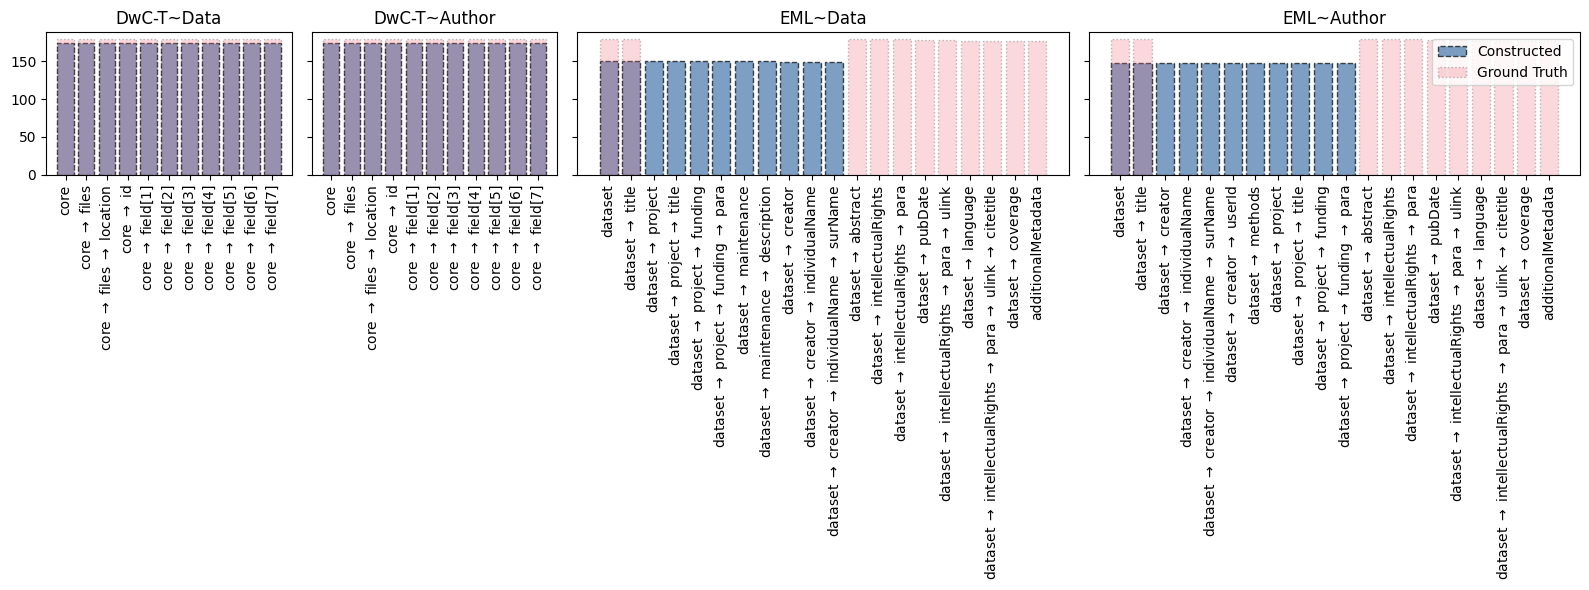

In [479]:
fig,axs = plt.subplots(1, 4, figsize=(16,6), sharey=True, width_ratios=(1,1,2,2))

for i, (ax, (g, cons_rs), (_, gt_rs)) in enumerate(zip(axs, cons_node_info_groups.items(), gt_node_info_groups.items())):
    cons_top_k = (
        cons_rs[cons_rs["path"] != "."]["path"]
            # .apply(lambda t: all_paths_groups[g]["mapper_key_to_idx"][str(t)])
            .apply(lambda t: "<!-- ... -->" if (st:=str(t)) and "Comment" in st else " $\\rightarrow$ ".join(re.sub(r"\{[^\{]+\}", "", st).split("/")))
            .value_counts().nlargest(TOP_K)
    )
    gt_top_k = (
        gt_rs[gt_rs["path"] != "."]["path"]
            # .apply(lambda t: all_paths_groups[g]["mapper_key_to_idx"][str(t)])
            .apply(lambda t: "<!-- ... -->" if (st:=str(t)) and "Comment" in st else " $\\rightarrow$ ".join(re.sub(r"\{[^\{]+\}", "", st).split("/")))
            .value_counts().nlargest(TOP_K)
    )

    print(f"{cons_top_k=}")
    print(f"{gt_top_k=}")

    ax.set_title(g)
    ax.tick_params("x", rotation=90)
    
    ax.bar(cons_top_k.index, cons_top_k, alpha=0.7, label="Constructed", ls="--", lw=1, edgecolor="black")
    ax.bar(gt_top_k.index, gt_top_k, alpha=0.25, label="Ground Truth", ls=":", lw=1, edgecolor="black")
    
    ax.legend() if i == 3 else ...
    
plt.tight_layout()
plt.show()

#### Descriptive Stats

In [480]:
print("Constructed VS Ground Truth: Tree Structural Similarity\n")

for g, rs in result_groups.items():
    print(f"--- {g} ----")
    display(result_groups[g][["cons_vs_gt_tree.apted_tree_edit_distance.sim_score", "cons_vs_gt_tree.tag_jaccard_index", "cons_vs_gt_tree.path_jaccard_index"]].describe())

Constructed VS Ground Truth: Tree Structural Similarity

--- DwC-T~Data ----


,cons_vs_gt_tree.apted_tree_edit_distance.sim_score,cons_vs_gt_tree.tag_jaccard_index,cons_vs_gt_tree.path_jaccard_index
count,174.000000,174.000000,174.000000
mean,0.968317,0.998643,0.957505
std,0.029243,0.012642,0.112452
min,0.833333,0.875000,0.412371
25%,0.958762,1.000000,1.000000
50%,0.980196,1.000000,1.000000
75%,0.987095,1.000000,1.000000
max,1.000000,1.000000,1.000000


--- DwC-T~Author ----


,cons_vs_gt_tree.apted_tree_edit_distance.sim_score,cons_vs_gt_tree.tag_jaccard_index,cons_vs_gt_tree.path_jaccard_index
count,174.000000,174.000000,174.000000
mean,0.964434,0.997206,0.949723
std,0.034290,0.022696,0.122653
min,0.790698,0.750000,0.402062
25%,0.951083,1.000000,0.980343
50%,0.979167,1.000000,1.000000
75%,0.986111,1.000000,1.000000
max,0.994186,1.000000,1.000000


--- EML~Data ----


,cons_vs_gt_tree.apted_tree_edit_distance.sim_score,cons_vs_gt_tree.tag_jaccard_index,cons_vs_gt_tree.path_jaccard_index
count,150.000000,150.000000,150.000000
mean,0.230780,0.235070,0.081606
std,0.089972,0.040104,0.038189
min,0.027696,0.133333,0.012530
25%,0.167198,0.209877,0.055609
50%,0.226959,0.236257,0.075551
75%,0.281091,0.256332,0.105430
max,0.468468,0.405797,0.224138


--- EML~Author ----


,cons_vs_gt_tree.apted_tree_edit_distance.sim_score,cons_vs_gt_tree.tag_jaccard_index,cons_vs_gt_tree.path_jaccard_index
count,148.000000,148.000000,148.000000
mean,0.223122,0.234775,0.080626
std,0.092062,0.039603,0.041894
min,0.007704,0.145161,0.002680
25%,0.167953,0.201899,0.052579
50%,0.218034,0.236978,0.074856
75%,0.286561,0.265656,0.100942
max,0.500000,0.346667,0.250000


In [481]:
print("Edit Distance Breakdowns\n")

for g, rs in tree_edit_breakdown_groups.items():
    print(f"--- {g} ----")
    display(rs.describe())

Edit Distance Breakdowns

--- DwC-T~Data ----


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,174.000000,174.000000,174.000000,174.000000,174.000000,174.000000,169.000000
mean,0.712644,0.816092,1.701149,46.735632,49.965517,3.229885,89.130178
std,1.692609,1.887156,1.471226,22.381846,23.894977,3.506233,53.073575
min,0.000000,0.000000,0.000000,11.000000,12.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,31.250000,34.000000,1.000000,42.000000
50%,0.000000,0.000000,1.000000,43.000000,45.500000,2.000000,87.000000
75%,0.000000,0.000000,2.000000,56.000000,62.000000,4.000000,136.000000
max,7.000000,12.000000,9.000000,188.000000,202.000000,19.000000,178.000000


--- DwC-T~Author ----


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,174.000000,174.000000,174.000000,174.000000,174.000000,174.000000,169.000000
mean,0.873563,1.034483,1.718391,46.614943,50.241379,3.626437,89.124260
std,1.922213,2.293233,1.400250,21.958342,23.743312,3.884695,52.258651
min,0.000000,0.000000,0.000000,11.000000,12.000000,1.000000,0.000000
25%,0.000000,0.000000,1.000000,31.250000,35.000000,1.000000,44.000000
50%,0.000000,0.000000,1.000000,43.000000,47.000000,2.000000,87.000000
75%,0.000000,1.000000,2.000000,56.000000,62.000000,5.000000,135.000000
max,9.000000,16.000000,9.000000,185.000000,202.000000,18.000000,178.000000


--- EML~Data ----


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,129.000000
mean,5.933333,223.613333,16.626667,19.900000,266.073333,246.173333,89.612403
std,3.490479,196.237248,9.115623,7.429986,196.597879,193.880948,56.728287
min,2.000000,10.000000,2.000000,8.000000,43.000000,35.000000,0.000000
25%,3.000000,108.000000,10.250000,14.000000,145.000000,131.000000,36.000000
50%,5.000000,168.500000,17.000000,17.000000,209.000000,187.500000,101.000000
75%,8.000000,284.000000,24.000000,26.000000,331.250000,301.750000,142.000000
max,21.000000,1637.000000,37.000000,51.000000,1671.000000,1650.000000,178.000000


--- EML~Author ----


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,148.000000,148.000000,148.000000,148.000000,148.000000,148.000000,123.000000
mean,5.141892,274.790541,15.229730,19.722973,314.885135,295.162162,95.268293
std,2.955475,540.316816,8.706159,6.051728,540.173473,539.508646,55.125650
min,2.000000,4.000000,2.000000,6.000000,46.000000,40.000000,0.000000
25%,3.000000,109.500000,8.000000,15.000000,148.750000,130.000000,44.000000
50%,4.000000,177.500000,16.000000,18.000000,212.500000,192.000000,110.000000
75%,7.000000,287.500000,22.000000,25.000000,333.000000,304.500000,143.500000
max,16.000000,6295.000000,38.000000,37.000000,6329.000000,6311.000000,178.000000
